# 제조업 실시간 이상 탐지 시스템 구축 실습 — 직접 해보기

과제 원본 코드(`6. 제조업 실시간 이상 탐지 시스템 구축 실습 [프로젝트].ipynb`)를 **흐름 단위로 묶어** 놓았다.
한 흐름을 끝까지 실행한 뒤, 그 아래 **✍️ 내 코멘트** 칸에 무엇을 했고 무엇을 알게 됐는지 적는다.

흐름마다 붙어 있는 칸
- **📖 코드 설명**: 코드가 무슨 일을 하는지
- **💡 생각해 볼 점**: 코드 리뷰할 때 짚어 볼 만한 부분 (원본 코드의 특이점, 개선할 여지)
- **✍️ 내 코멘트**: 직접 작성

**실행 전 확인 (코랩)**
- 메뉴 **런타임 → 런타임 유형 변경**에서 **GPU**를 고른다. CPU로 돌리면 PaDiM·AutoEncoder가 매우 느리다.
- 데이터셋(약 1.9GB)은 코랩 서버의 `/content`에 받는다. 런타임이 끊기면 지워지므로, 다시 접속하면 흐름 2부터 다시 받는다(1\~2분).
- 코드는 원본 그대로다. 코랩에서 그대로 안 되는 줄만 `# 📄 원본`과 `# ☁️ 코랩용`을 나란히 적었다.
- 시간이 오래 걸리는 셀: 흐름 14(세 모델 학습·평가, T4에서 약 15분).

## 🗺️ 전체 흐름 한눈에

| 파트 | 흐름 | 하는 일 |
|---|---|---|
| A. 데이터 준비 | 1\~2 | 라이브러리 설치 → VisA 데이터셋 받기·구조 확인 |
| B. 데이터 로더와 시각화 | 3\~6 | Dataset 클래스 → 전처리·DataLoader → 샘플·통계·마스크 그려 보기 |
| C. 세 가지 이상 탐지 모델 비교 | 7\~15 | 특징 추출기 → PaDiM / AutoEncoder / One-Class SVM → 평가 지표 → 학습·비교 그래프 |
| D. 실시간 추론 웹 앱 | 16\~21 | PaDiM 학습·저장 → 저장된 모델 불러와 한 장씩 추론 → Gradio 웹 화면 |

**이상 탐지가 일반 분류와 다른 점** (강의 7쪽)

| 구분 | 일반 분류 | 이상 탐지 |
|---|---|---|
| 학습 데이터 | 정상 + 불량을 고르게 | **주로 정상만** |
| 목표 | 클래스 맞히기 | 정상 범위를 배우고, 벗어나면 이상 |
| 평가 | 전체 정확도 | 이상 탐지율 vs 오탐률 (AUROC 등) |

이번 실습의 세 모델은 모두 **정상 이미지만으로 학습**하고, 테스트 이미지마다 **이상 점수(anomaly score)** 를 낸다. 점수가 높을수록 이상하다는 뜻이고, 어디서부터 불량으로 볼지(임계값)는 사람이 정한다.

```
정상 이미지만 ─▶ 모델이 "정상"을 배움
테스트 이미지 ─▶ 이상 점수 ─▶ 임계값보다 크면 "불량"으로 판정
                 PaDiM: 패치별 마할라노비스 거리의 최댓값
                 AutoEncoder: 복원 오차(MSE)
                 One-Class SVM: 정상 경계에서 벗어난 정도
```

판정은 모델의 추측이라 틀릴 수 있다. 정상인데 불량으로 판정하면 **오탐**, 불량인데 정상으로 판정하면 **미탐**이다(흐름 15의 개인 실험에서 실제 사례를 볼 수 있다).

# 파트 A. 데이터 준비

## 흐름 1. 라이브러리 설치
이상 탐지에 필요한 라이브러리를 설치한다.

**📖 코드 설명**
- `anomalib`, `pytorch-lightning`: 이상 탐지 모델을 모아 둔 라이브러리와 그 학습 도구다. 원본에서도 주석 처리되어 있고, 이번 실습은 PaDiM 등을 **직접 구현**하므로 쓰지 않는다.
- `wget`: 주소에서 파일을 받는 파이썬 패키지. 흐름 2의 `wget.download(...)`에 쓴다.
- 나머지(`torch`, `torchvision`, `sklearn`, `cv2`, `seaborn`, `pandas`)는 코랩에 이미 깔려 있다.

### 이상탐지를 위한 라이브러리 설치

In [1]:
# !pip install anomalib
# !pip install pytorch-lightning

In [2]:
# 📄 원본: # !pip install wget
# ☁️ 코랩용: 코랩에는 wget 파이썬 패키지가 없어서 주석을 풀었다 (다음 셀의 import wget에 필요)
!pip install wget

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=aaf31cc34cf0bfeae1416d0beae2b801f00341082116da3348055deacd404a73
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


**💡 생각해 볼 점**
- 원본은 `wget` 설치 줄까지 주석인데, 코랩에는 `wget`이 없다(주석을 풀고 실행하니 `Successfully installed wget-3.2`로 새로 설치됐다). 그대로 실행했다면 흐름 2의 `import wget`에서 에러가 났을 것이다.

> ✍️ **내 코멘트**
>
> 원본은 설치 줄이 전부 주석이라 코랩에서 그대로 돌리면 다음 셀의 `import wget`에서 에러가 난다. wget 설치 줄만 주석을 풀었다.

## 흐름 2. VisA 데이터셋 받기와 구조 확인
 이상 탐지 데이터셋 **VisA(Visual Anomaly)** 를 받아 압축을 풀고, 카테고리별 정상 이미지 수를 센다.

**📖 코드 설명**
- `download_visa_dataset()`
  - `VisA_20220922.tar`(약 1.9GB)가 없을 때만 받는다(`os.path.exists`). 다시 실행해도 또 받지 않는다
- VisA 구성 (강의 29쪽): 12개 카테고리(PCB 4종, 마카로니 2종, 캡슐, 양초, 캐슈너트, 껌, 프라이엄 2종). 결함 유형은 균열·긁힘·구멍·누락 등이고, 불량 이미지마다 **픽셀 단위 마스크**(어디가 불량인지 흰색으로 칠한 이미지)가 있다.

```
VisA/
├── pcb4/
│   ├── Data/Images/Normal/   ← 정상 이미지
│   ├── Data/Images/Anomaly/  ← 불량 이미지
│   ├── Data/Masks/Anomaly/   ← 불량 위치 마스크
│   └── image_anno.csv        ← 이미지 경로, 라벨, 마스크 경로 목록
├── capsules/ ...
└── split_csv/                ← 카테고리가 아닌 폴더 (이름으로 보아 train/test 나누기 정보)
```

## VisA 데이터셋 다운로드

In [3]:
import os
import wget
import zipfile
from pathlib import Path
import pandas as pd
import tarfile

def download_visa_dataset():
    """VisA 데이터셋 다운로드"""
    base_url = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
    filename = "VisA_20220922.tar"
    extract_dir = "./VisA"


    if not os.path.exists(filename):
        print("VisA 데이터셋 다운로드 중...")
        wget.download(base_url, filename)
        print("\n다운로드 완료!")

    ## 압축 해제
    if not os.path.exists(extract_dir):
        os.makedirs(extract_dir, exist_ok=True)
        with tarfile.open(filename, 'r') as tar:
            tar.extractall(path=extract_dir)
        print("압축 해제 완료!")

def check_visa_structure(data_path="./VisA_pytorch/VisA"):
    """VisA 데이터셋 구조 확인"""
    data_path = Path(data_path)
    print(f"VisA 데이터셋 경로: {data_path}")

    categories = []
    for category_dir in data_path.iterdir():
        if category_dir.is_dir():
            categories.append(category_dir.name)
            print(f"\n카테고리: {category_dir.name}")

            # 이미지 개수 확인
            images_dir = category_dir / "Data" / "Images"
            if images_dir.exists():
                normal_count = len(list((images_dir / "Normal").glob("*"))) if (images_dir / "Normal").exists() else 0


                print(f"  정상 이미지: {normal_count}개")

    return categories

In [4]:
download_visa_dataset()

VisA 데이터셋 다운로드 중...

다운로드 완료!


/tmp/ipykernel_1084/1396103325.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


압축 해제 완료!


In [ ]:
check_visa_structure(data_path="./VisA")

VisA 데이터셋 경로: VisA

카테고리: macaroni1
  정상 이미지: 1000개

카테고리: fryum
  정상 이미지: 500개

카테고리: capsules
  정상 이미지: 602개

카테고리: macaroni2
  정상 이미지: 1000개

카테고리: pipe_fryum
  정상 이미지: 500개

카테고리: pcb4
  정상 이미지: 1005개

카테고리: candle
  정상 이미지: 1000개

카테고리: chewinggum
  정상 이미지: 503개

카테고리: split_csv

카테고리: pcb3
  정상 이미지: 1006개

카테고리: cashew
  정상 이미지: 500개

카테고리: pcb2
  정상 이미지: 1001개

카테고리: pcb1
  정상 이미지: 1004개


['macaroni1',
 'fryum',
 'capsules',
 'macaroni2',
 'pipe_fryum',
 'pcb4',
 'candle',
 'chewinggum',
 'split_csv',
 'pcb3',
 'cashew',
 'pcb2',
 'pcb1']

In [ ]:
# 🧪 [개인 실험] 원본에 없는 셀: 위 출력에는 정상 이미지 수만 나와서, 불량 데이터 비율이 궁금해 Anomaly 폴더도 세어 봤다
total_normal, total_anomaly = 0, 0
for category in sorted(os.listdir("./VisA")):
    images_dir = Path("./VisA") / category / "Data" / "Images"
    if not images_dir.exists():  # split_csv 같은 폴더는 건너뛴다
        continue
    normal = len(list((images_dir / "Normal").glob("*")))
    anomaly = len(list((images_dir / "Anomaly").glob("*")))
    total_normal += normal
    total_anomaly += anomaly
    print(f"{category:12s} 정상 {normal:5d}장  불량 {anomaly:4d}장  불량 비율 {anomaly / (normal + anomaly):.1%}")

print(f"\n전체: 정상 {total_normal}장, 불량 {total_anomaly}장, 불량 비율 {total_anomaly / (total_normal + total_anomaly):.1%}")

candle       정상  1000장  불량  100장  불량 비율 9.1%
capsules     정상   602장  불량  100장  불량 비율 14.2%
cashew       정상   500장  불량  100장  불량 비율 16.7%
chewinggum   정상   503장  불량  100장  불량 비율 16.6%
fryum        정상   500장  불량  100장  불량 비율 16.7%
macaroni1    정상  1000장  불량  100장  불량 비율 9.1%
macaroni2    정상  1000장  불량  100장  불량 비율 9.1%
pcb1         정상  1004장  불량  100장  불량 비율 9.1%
pcb2         정상  1001장  불량  100장  불량 비율 9.1%
pcb3         정상  1006장  불량  100장  불량 비율 9.0%
pcb4         정상  1005장  불량  100장  불량 비율 9.0%
pipe_fryum   정상   500장  불량  100장  불량 비율 16.7%

전체: 정상 9621장, 불량 1200장, 불량 비율 11.1%


**💡 생각해 볼 점**

- 원본 출력에는 정상 이미지 수만 나와서 개인 실험으로 불량도 세어 봤다. 정상은 500\~1,000장인데 불량은 12개 카테고리 모두 100장뿐이고, 불량 비율은 9\~17%(전체 11.1%)다. 강의에서 말한 **데이터 불균형**(정상 99% vs 불량 1%)만큼은 아니지만 데이터셋에도 불균형이 보인다.
- `import zipfile`은 쓰지 않는다(tar 파일이라 `tarfile`을 쓴다).

> ✍️ **내 코멘트**
>
> VisA 데이터셋(약 1.9GB)을 받아 압축을 풀고 카테고리별 정상 이미지 수를 확인했다. 개인 실험으로 불량도 세어 보니 카테고리마다 100장뿐이라 불량 비율이 9\~17%(전체 11.1%)였다. 강의에서 말한 현장(불량 1%)만큼은 아니지만 데이터 불균형이 있다.

# 파트 B. 데이터 로더와 시각화

## 흐름 3. VisA 전용 Dataset 클래스 만들기
번호를 주면 이미지 한 장(과 라벨·마스크)을 꺼내 주는 `Dataset` 클래스를 만든다.

**📖 코드 설명**
- `image_anno.csv`에서 이미지 경로, 라벨(`normal` 또는 결함 이름), 마스크 경로를 읽는다.
- **학습/테스트 나누기** (`train_ratio=0.8`)
  - 학습: 정상 이미지의 앞 80%만 → 이상 탐지는 **정상만으로 학습**한다.
  - 테스트: 나머지 정상 20% + **불량 전부**
  - pcb4: 학습 804장, 테스트 301장(정상 201 + 불량 100)
- 라벨은 정상 `0`, 불량 `1`로 바꾼다.

### Dataloader 구현

In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
import numpy as np

class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

**💡 생각해 볼 점**
- 정상 이미지를 **섞지 않고 앞에서부터** 80%를 자른다. 데이터셋에 들어 있는 `split_csv` 폴더도 쓰지 않고 직접 나눠서, 다른 결과와 바로 비교하기 어렵다.

> ✍️ **내 코멘트**
>
> 정상 앞 80%는 학습, 나머지 정상과 불량 전부는 테스트로 나눈다. 학습에 불량을 한 장도 안 쓰는 게 일반 분류와 가장 큰 차이다. 다만 섞지 않고 앞에서부터 잘라서, 공식 나누기를 쓴 논문 결과와 바로 비교하긴 어렵다.

## 흐름 4. 전처리 정의와 DataLoader 만들기
이미지를 모델 입력 모양으로 바꾸는 규칙(transform)을 정하고, 학습용·테스트용 DataLoader를 만든다.

**📖 코드 설명**
- `Resize((256, 256))` → `ToTensor()`(0\~1 실수) → `Normalize`(ImageNet 평균·표준편차). 사전학습된 ResNet이 이 값으로 학습되어서 맞춰 준다. 정규화 후 값은 대략 **-2.1\~2.6**이다.
- `RandomHorizontalFlip(p=0.5)`: **학습용에만** 50% 확률로 좌우를 뒤집는다(데이터 증강).
- `shuffle=True`는 학습용만. 테스트는 섞지 않아 라벨 순서가 유지된다.

In [6]:
# 데이터 전처리 정의
def get_visa_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    test_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, test_transform


In [7]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


**💡 생각해 볼 점**
- 부품 배치가 정해진 PCB에서 좌우 뒤집기는 오히려 "이상"한 모습이다. 위치마다 정상을 배우는 PaDiM에는 맞지 않는다(파트 D에서는 뒤집기를 뺀다).

> ✍️ **내 코멘트**
>
> 256 크기로 맞추고 ImageNet 값으로 정규화한다. 학습용에만 좌우 뒤집기가 있는데, 부품 위치가 정해진 PCB에서는 뒤집힌 모습이 오히려 이상한 모습이라 맞지 않는 것 같다.

## 흐름 5. 시각화 함수 정의
샘플 이미지, 마스크 겹쳐 보기, 데이터 통계를 그리는 함수 세 개를 만든다. (실행은 흐름 6)

**📖 코드 설명**
- 정규화된 텐서를 그리려면 `image * std + mean`으로 **정규화를 되돌린** 뒤 그린다.
- `visualize_with_mask`: 원본 / 마스크 / 겹쳐 보기(불량 부분을 빨간색으로)
- `plot_visa_statistics`: 정상 vs 불량 비율, 결함 유형, 마스크 유무, 라벨 상위 10개

## 시각화

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

def visualize_visa_samples(dataset, num_samples=8):
    """VisA 데이터셋 샘플 시각화"""
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for i, idx in enumerate(indices):
        sample = dataset[idx]
        image = sample['image']
        label = sample['label']
        defect_type = sample['defect_type']

        # 텐서를 이미지로 변환
        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0)
            image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
            image = torch.clamp(image, 0, 1)

        axes[i].imshow(image)
        title = f"{'Normal' if label == 0 else 'Anomaly'}"
        if defect_type != 'normal':
            title += f"\n({defect_type})"
        axes[i].set_title(title)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def visualize_with_mask(dataset, idx):
    """이미지와 마스크 함께 시각화"""
    sample = dataset[idx]
    image = sample['image']
    mask = sample.get('mask')
    label = sample['label']
    defect_type = sample['defect_type']

    # 이미지 정규화 해제
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
        image = torch.clamp(image, 0, 1)

    if mask is not None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # 원본 이미지
        axes[0].imshow(image)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        # 마스크
        axes[1].imshow(mask.squeeze(), cmap='gray')
        axes[1].set_title('Anomaly Mask')
        axes[1].axis('off')

        # 오버레이
        overlay = image.clone()
        if mask.sum() > 0:
            mask_resized = torch.nn.functional.interpolate(
                mask.unsqueeze(0),
                size=image.shape[:2],
                mode='nearest'
            ).squeeze()
            overlay[mask_resized > 0.01] = torch.tensor([255.0, 0.0, 0.0])  # 빨간색으로 표시

        axes[2].imshow(overlay)
        axes[2].set_title(f'Overlay ({defect_type})')
        axes[2].axis('off')

    else:
        plt.figure(figsize=(8, 6))
        plt.imshow(image)
        plt.title(f"{'Normal' if label == 0 else 'Anomaly'} - {defect_type}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
def plot_visa_statistics(data_path, category):
    """VisA 데이터셋 통계 시각화"""
    category_path = Path(data_path) / category
    csv_path = category_path / "image_anno.csv"

    if csv_path.exists():
        df = pd.read_csv(csv_path)

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        title1 = 'Overall Class Distribution (Normal vs Anomaly)'
        title2 = 'Main Defect Types Distribution'
        title3 = 'Mask Availability Distribution'
        title4 = 'All Labels Distribution (Top 10)'
        xlabel2 = 'Number of Images'
        ylabel3 = 'Number of Images'
        xlabel4 = 'Number of Images'
        mask_labels = ['With Mask', 'Without Mask']

        # 전체 클래스 분포 (정상 vs 비정상)
        binary_labels = ['Normal' if label == 'normal' else 'Anomaly' for label in df['label']]
        class_counts = pd.Series(binary_labels).value_counts()
        axes[0, 0].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
        axes[0, 0].set_title(title1)

        # 결함 유형별 상세 분포
        anomaly_df = df[df['label'] != 'normal']
        if not anomaly_df.empty:
            # 결함 유형을 단순화 (콤마로 구분된 경우 첫 번째만 사용)
            simplified_defects = [label.split(',')[0] for label in anomaly_df['label']]
            defect_counts = pd.Series(simplified_defects).value_counts()

            axes[0, 1].barh(defect_counts.index, defect_counts.values)
            axes[0, 1].set_title(title2)
            axes[0, 1].set_xlabel(xlabel2)

        # 마스크 유무 분포
        mask_counts = df['mask'].notna().value_counts()
        mask_labels_mapped = [mask_labels[0] if has_mask else mask_labels[1] for has_mask in mask_counts.index]
        axes[1, 0].bar(mask_labels_mapped, mask_counts.values)
        axes[1, 0].set_title(title3)
        axes[1, 0].set_ylabel(ylabel3)

        # 전체 결함 유형 (복합 결함 포함)
        all_defect_counts = df['label'].value_counts()
        # 상위 10개만 표시
        top_defects = all_defect_counts.head(10)
        axes[1, 1].barh(range(len(top_defects)), top_defects.values)
        axes[1, 1].set_yticks(range(len(top_defects)))
        axes[1, 1].set_yticklabels(top_defects.index)
        axes[1, 1].set_title(title4)
        axes[1, 1].set_xlabel(xlabel4)

        plt.tight_layout()
        plt.show()

        # 데이터 요약 출력

        print(f"Total images: {len(df)}")
        print(f"Normal images: {len(df[df['label'] == 'normal'])}")
        print(f"Anomaly images: {len(df[df['label'] != 'normal'])}")
        print(f"Images with masks: {df['mask'].notna().sum()}")
        print(f"Unique defect types: {df['label'].nunique()}")

    else:
        error_msg = f"CSV 파일을 찾을 수 없습니다: {csv_path}" if KOREAN_FONT_AVAILABLE else f"CSV file not found: {csv_path}"
        print(error_msg)


**💡 생각해 볼 점**
- 겹쳐 보기에서 빨간색을 `[255.0, 0.0, 0.0]`으로 칠하는데 이미지는 0\~1 범위라 `Clipping` 경고가 뜬다. `[1.0, 0.0, 0.0]`이면 된다.
- CSV가 없을 때 쓰는 `KOREAN_FONT_AVAILABLE` 변수가 정의되어 있지 않아 그 경로로 가면 에러가 난다.

> ✍️ **내 코멘트**
>
> 정규화된 이미지는 그대로 그리면 색이 이상해서 되돌린 뒤 그린다. 마스크를 겹칠 때 빨간색을 255로 칠해서 0\~1 범위를 넘어 경고가 뜬다.

## 흐름 6. 설정값 정하고 데이터 그려 보기
실습 전체에서 쓸 설정값을 정하고, 샘플·통계·마스크를 그린다.

**📖 코드 설명**
- `CATEGORY_NAME = "pcb4"`(PCB 4번), `BATCH_SIZE = 8`, `D_REDUCED = 100`(PaDiM 축소 차원), `PADIM_PATCH_SIZE = 28`. 파트 D에서도 쓴다.
- 테스트셋은 **정상 201장이 앞, 불량 100장이 뒤**라서 `visualize_with_mask(..., 210)`은 불량 이미지다.

In [8]:
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE, include_mask=True)

CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개


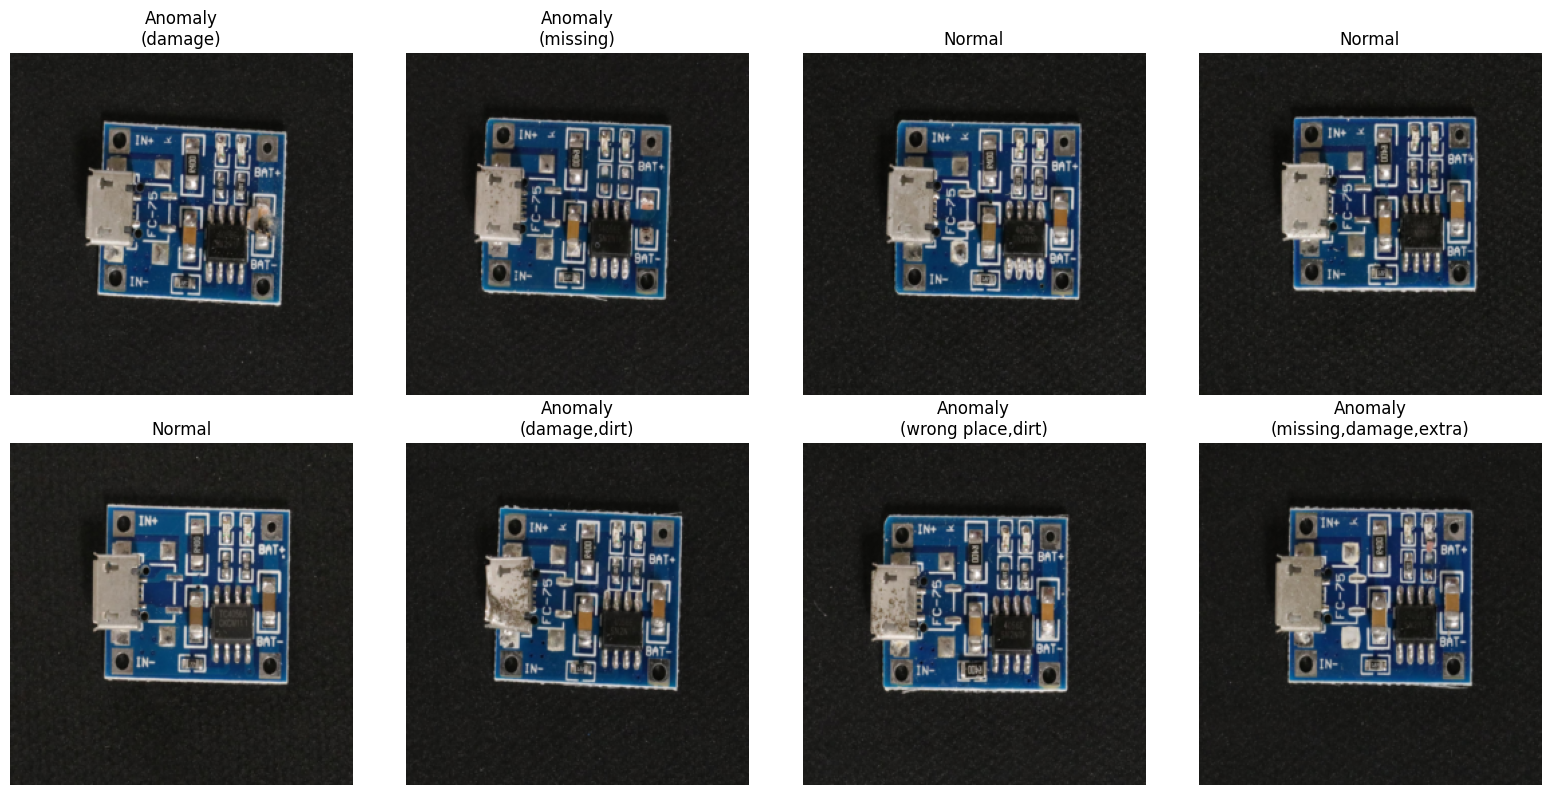

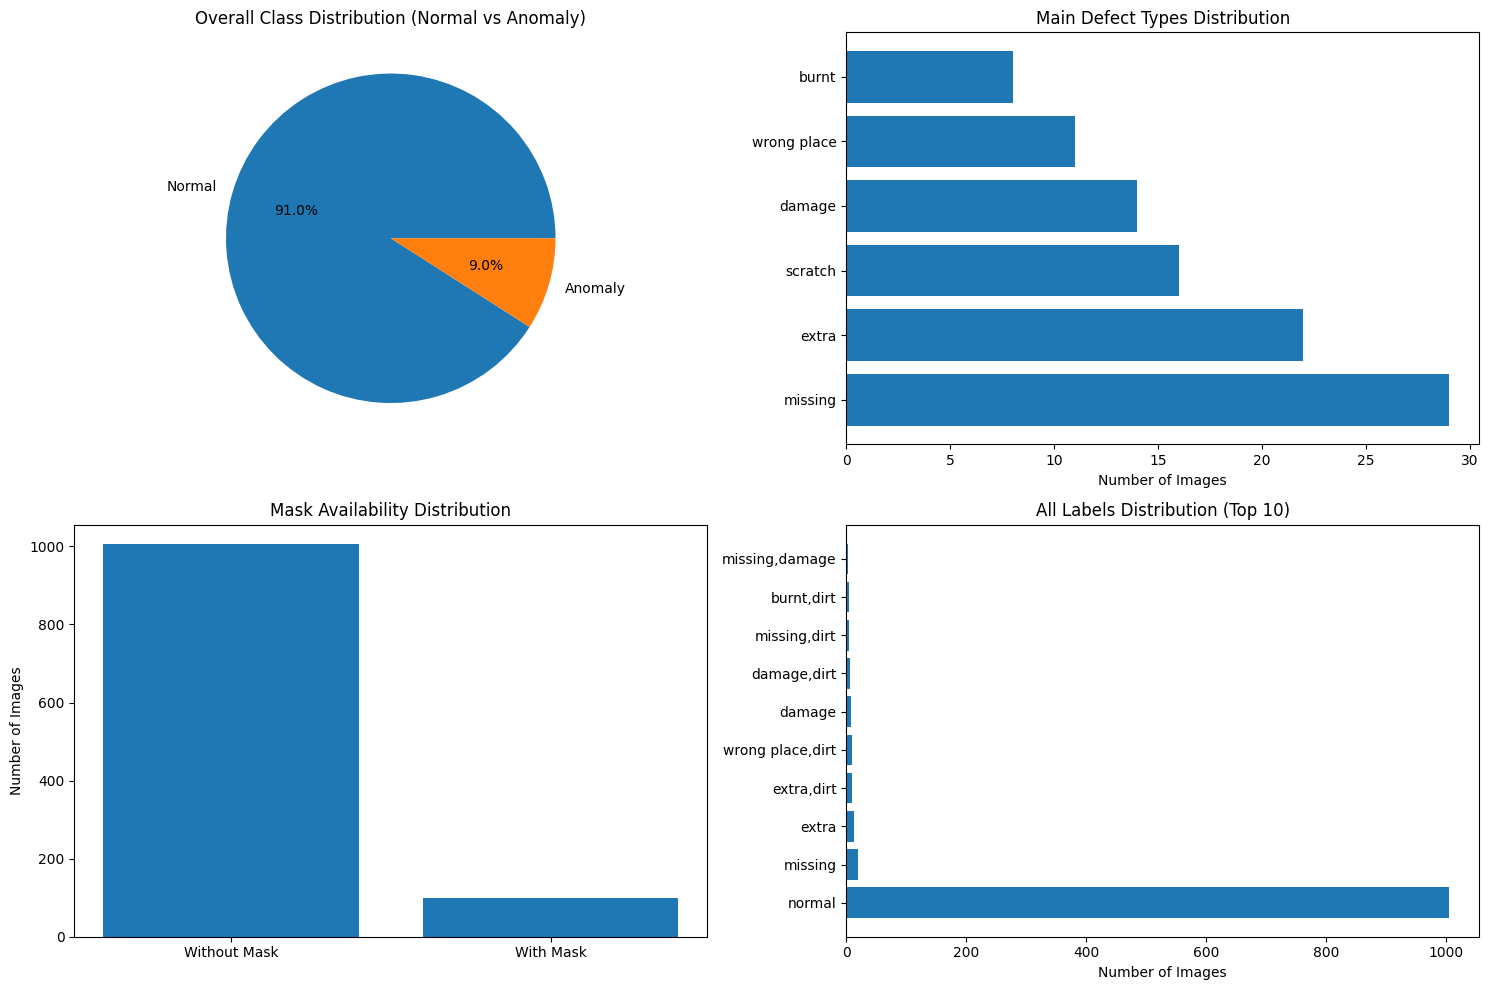

Total images: 1105
Normal images: 1005
Anomaly images: 100
Images with masks: 100
Unique defect types: 27


In [ ]:
visualize_visa_samples(test_loader.dataset)
plot_visa_statistics(DATA_PATH, CATEGORY_NAME)

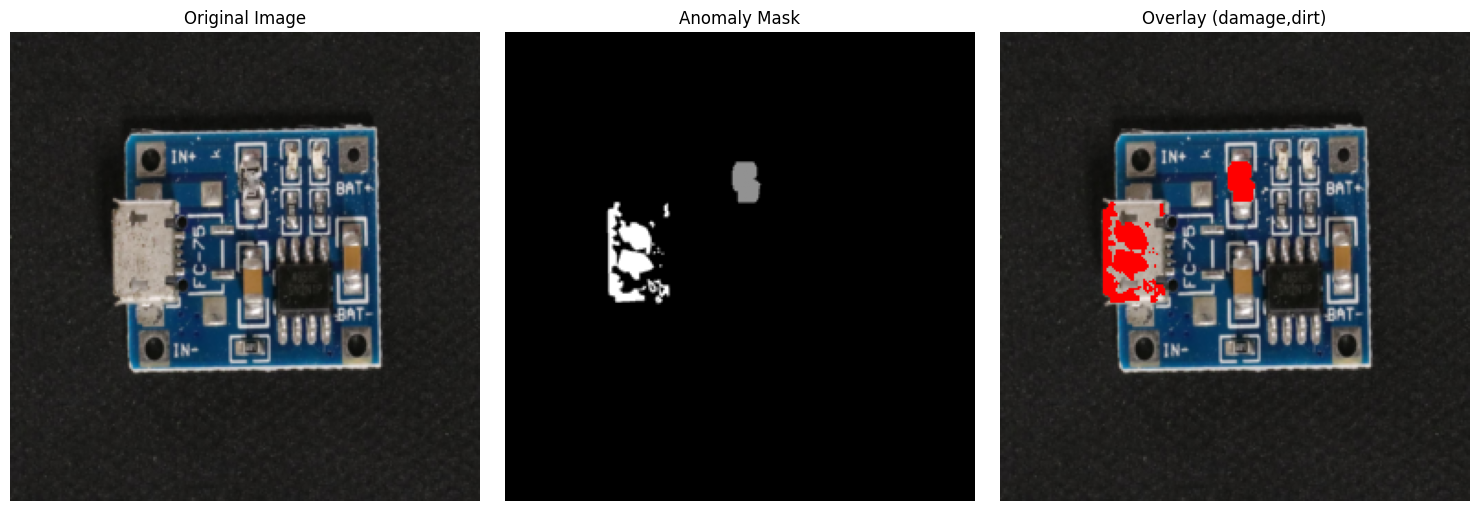

In [ ]:
visualize_with_mask(test_loader.dataset, 210)

**💡 생각해 볼 점**
- 테스트셋은 301장 중 100장(33%)이 불량이라, 실제 공장보다 불량 비율이 훨씬 높은 조건에서 평가한다.

> ✍️ **내 코멘트**
>
> pcb4는 학습 804장, 테스트 301장(불량 100장)이다. 테스트셋은 정상이 앞쪽이라 210번은 불량 이미지라서 마스크도 같이 나온다. 테스트셋의 불량이 33%라서, 실제 공장보다 불량이 훨씬 많은 조건에서 평가하는 셈이다.

# 파트 C. 세 가지 이상 탐지 모델 비교

## 흐름 7. 모델 라이브러리 불러오기와 GPU 확인
모델 구현과 평가에 쓸 라이브러리를 불러오고, GPU를 쓸 수 있는지 확인한다.

**📖 코드 설명**
- `sklearn.metrics`: AUROC·AUPRC 계산, `OneClassSVM`: 흐름 11에서 사용
- `사용 장치: cuda`가 나와야 GPU를 쓰는 것이다.

## 모델 구현

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# GPU 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 장치: {device}")


사용 장치: cuda


**💡 생각해 볼 점**
- `warnings.filterwarnings('ignore')`로 경고를 모두 꺼서, 알아 둘 만한 경고도 숨겨진다.

> ✍️ **내 코멘트**
>
> GPU(cuda)를 쓰는 것을 확인했다. 경고를 전부 꺼 둬서 알아야 할 경고도 보이지 않는다.

## 흐름 8. 특징 추출기 (FeatureExtractor)
ImageNet으로 학습된 **Wide ResNet-50**에서 중간 층(layer2, layer3)의 출력(특징맵)을 꺼내는 도구를 만든다. PaDiM과 One-Class SVM이 이 특징을 쓴다.

**📖 코드 설명**
- 사전학습 모델은 **다시 학습하지 않고** 특징만 빌려 쓴다(`requires_grad = False`, `eval()`).
- **forward hook**: 특정 층이 계산을 끝낼 때마다 그 출력을 저장하게 걸어 두는 장치
- 입력 256×256일 때: layer2 = 512채널·32×32, layer3 = 1024채널·16×16 → 위치마다 **1,536차원** 특징

In [18]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)

**💡 생각해 볼 점**
- `pretrained=True`는 곧 없어질 방식이다. 새 방식은 `weights=models.Wide_ResNet50_2_Weights.IMAGENET1K_V1`.
- layer3까지만 필요한데 모델 끝(layer4, fc)까지 계산한다.

> ✍️ **내 코멘트**
>
> 사전학습된 Wide ResNet-50을 학습 없이 특징 추출에만 쓴다. layer2와 layer3 출력을 합쳐 위치마다 1,536차원 특징을 만든다. `pretrained=True`는 곧 없어질 방식이라 `weights=`로 바꾸는 게 좋다.

## 흐름 9. PaDiM (Patch Distribution Modeling)
**위치(패치)마다** 정상 특징의 분포(평균·공분산)를 배우고, 테스트 패치가 그 분포에서 얼마나 벗어났는지로 이상 점수를 낸다. (강의 33\~35쪽)

**📖 코드 설명**
- **학습(`fit`)**: 특징맵을 28×28 칸으로 맞춤 → 전체 `[804장 × 784칸, 1536]` → 무작위 행렬로 **100차원**으로 줄임 → 784개 위치마다 평균과 공분산(역행렬)을 저장
- **추론(`predict`)**: 위치마다 마할라노비스 거리를 재고, 784개 중 **최댓값**이 이미지의 이상 점수
- 마할라노비스 거리: 원래 많이 흔들리는 방향의 차이는 작게, 거의 안 흔들리는 방향의 차이는 크게 치는 거리

In [19]:
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        """정상 데이터로 모델 훈련"""
        print("PaDiM 훈련 시작...")

        # 모든 훈련 데이터에서 특징 추출
        all_features = []

        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        # 단일 이미지 특징 추출
                        single_feat = feat[i:i+1]  # [1, C, H, W]

                        # 28x28로 리사이즈
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))

                        # 패치별 특징으로 변환 [784, C]
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    # 레이어별 특징 결합 [784, total_channels]
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        # 모든 특징을 하나로 결합 [N*784, total_channels]
        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        # 차원 축소를 위한 Random Projection 행렬 생성
        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            # 정규화
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)

            # 차원 축소 적용
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        # 패치 위치별로 분리하여 통계 계산
        n_samples = len(all_features) // (28 * 28)

        for patch_idx in range(28 * 28):
            # 특정 패치 위치의 모든 특징 추출
            patch_features = all_features[patch_idx::28*28]  # [n_samples, d_reduced]

            # 평균과 공분산 계산
            mean = torch.mean(patch_features, dim=0)

            # 공분산 행렬 계산 (정규화 추가)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)

            # 수치 안정성을 위한 정규화
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4

            # 역행렬 계산
            try:
                inv_cov = torch.linalg.inv(cov)
            except:
                # 특이행렬인 경우 pseudo-inverse 사용
                inv_cov = torch.linalg.pinv(cov)

            self.means.append(mean)
            self.inv_covariances.append(inv_cov)

        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        anomaly_scores = []

        for batch in tqdm(test_loader, desc="이상 탐지 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    combined_features = torch.cat(img_features, dim=1)

                    # 차원 축소 (훈련 시와 동일한 방식)
                    if self.projection_matrix is not None:
                        combined_features = torch.mm(combined_features, self.projection_matrix)

                    # 각 패치별 Mahalanobis 거리 계산
                    patch_scores = []
                    for patch_idx in range(28 * 28):
                        diff = combined_features[patch_idx] - self.means[patch_idx]

                        # Mahalanobis 거리 계산
                        mahal_dist = torch.sqrt(torch.mm(
                            torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                            diff.unsqueeze(1)
                        )).item()

                        patch_scores.append(mahal_dist)

                    # 전체 이상 점수 (최대값 사용)
                    anomaly_scores.append(max(patch_scores))

        return np.array(anomaly_scores), None

**💡 생각해 볼 점**
- `[630336, 1536]` 텐서가 GPU에서 약 3.9GB다. 강의에서 말한 "메모리 사용량이 클 수 있음"이 이 부분이다.
- 추론할 때 784개 위치를 하나씩 반복해서 계산한다. 흐름 14 출력을 보면 이상 탐지(19배치)가 학습 때 특징 추출(51배치)보다 배치 수는 적은데 더 오래 걸린다. 행렬 계산으로 한 번에 처리하면(`torch.einsum` 등) 반복을 줄일 수 있다.

> ✍️ **내 코멘트**
>
> 위치마다 정상 특징의 평균과 공분산을 저장해 두고, 테스트 패치가 얼마나 벗어났는지 마할라노비스 거리로 잰다. 가장 큰 거리가 이미지의 이상 점수다. 다만 특징을 GPU에 다 모아서 메모리를 많이 쓰고(약 3.9GB), 위치를 하나씩 반복해서 계산해서 추론이 학습보다 오래 걸린다.

## 흐름 10. CNN AutoEncoder
이미지를 작게 압축했다가 다시 **복원**하도록 학습한다. 정상만 배웠으니 불량은 잘 복원하지 못하고, 그 **복원 오차**를 이상 점수로 쓴다. (강의 36\~37쪽)

**📖 코드 설명**
- 인코더: 256×256 → **8×8×128**로 압축, 디코더: 다시 256×256×3으로 복원. 마지막 `Sigmoid`는 출력을 **0\~1**로 만든다.
- 입력과 복원 이미지의 차이(MSE)를 줄이도록 50에폭 학습하고, 이미지별 평균 오차가 이상 점수다.

In [10]:
class ConvAutoEncoder(nn.Module):
    def __init__(self, input_channels=3, latent_dim=128):
        super(ConvAutoEncoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, latent_dim, 4, stride=2, padding=1),  # 8x8
            nn.BatchNorm2d(latent_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, input_channels, 4, stride=2, padding=1),  # 256x256
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

class AutoEncoderAnomalyDetector:
    def __init__(self, input_size=(256, 256), latent_dim=128):
        self.model = ConvAutoEncoder(input_channels=3, latent_dim=latent_dim).to(device)
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.001)
        self.input_size = input_size

    def fit(self, train_loader, epochs=50):
        """AutoEncoder 훈련"""
        print("AutoEncoder 훈련 시작...")
        self.model.train()

        train_losses = []

        for epoch in range(epochs):
            epoch_loss = 0
            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
                images = batch['image'].to(device)

                self.optimizer.zero_grad()
                reconstructed = self.model(images)
                loss = self.criterion(reconstructed, images)
                loss.backward()
                self.optimizer.step()

                epoch_loss += loss.item()

            avg_loss = epoch_loss / len(train_loader)
            train_losses.append(avg_loss)
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.6f}")

        self.model.eval()
        print("AutoEncoder 훈련 완료!")
        return train_losses

    def predict(self, test_loader):
        """테스트 데이터에 대한 재구성 오차 계산"""
        self.model.eval()
        anomaly_scores = []

        with torch.no_grad():
            for batch in tqdm(test_loader, desc="이상 탐지 중"):
                images = batch['image'].to(device)
                reconstructed = self.model(images)

                # 픽셀별 재구성 오차
                reconstruction_errors = F.mse_loss(reconstructed, images, reduction='none')
                reconstruction_errors = reconstruction_errors.view(images.size(0), -1).mean(dim=1)

                anomaly_scores.extend(reconstruction_errors.cpu().numpy())

        return np.array(anomaly_scores)

**💡 생각해 볼 점**
- **입력과 출력 범위가 다르다**: 입력은 정규화로 약 -2.1\~2.6인데 출력은 `Sigmoid`라 0\~1밖에 못 낸다. 그래서 0보다 작거나 1보다 큰 픽셀은 절대 복원할 수 없고, 실제로 손실이 1.6 근처에서 더 내려가지 않았다. AUROC도 무작위(0.5)보다 낮게 나왔다. 흐름 14의 개인 실험에서 `Sigmoid`만 빼고 같은 조건으로 다시 학습하니 AUROC가 0.26 → 0.92로 올라, 이 구조 문제가 원인이었음을 확인했다.

> ✍️ **내 코멘트**
>
> 정상을 복원하도록 학습해서 복원 오차를 점수로 쓴다. 그런데 입력은 -2.1\~2.6 범위인데 출력은 0\~1이라 처음부터 제대로 복원할 수 없는 구조다. 흐름 14 개인 실험에서 Sigmoid를 빼자 AUROC가 0.92까지 올라 원인을 확인했다.

## 흐름 11. One-Class SVM
특징맵을 이미지 한 장당 **벡터 하나**로 요약하고, 정상 벡터들을 감싸는 **경계**를 배운다. 경계 밖이면 이상이다. (강의 38\~39쪽)

**📖 코드 설명**
- 특징맵 전체를 평균 내서 이미지당 1,536차원 벡터를 만들고, `StandardScaler`로 크기를 맞춘다.
- `OneClassSVM(nu=0.1, kernel='rbf')`: 학습 데이터의 최대 10%는 경계 밖이어도 된다고 허용
- 이상 점수 = `-decision_function(...)` (부호를 뒤집어 "클수록 이상"으로 맞춤)

In [ ]:
class OneClassSVMAnomalyDetector:
    def __init__(self, feature_extractor, nu=0.1):
        self.feature_extractor = feature_extractor
        self.svm = OneClassSVM(nu=nu, kernel='rbf', gamma='scale')
        self.scaler = StandardScaler()

    def extract_features(self, data_loader):
        """특징 추출"""
        features = []

        for batch in tqdm(data_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                feat_dict = self.feature_extractor(images)

                # 모든 레이어의 특징을 결합하고 평균 풀링
                combined_features = []
                for layer_name, feat in feat_dict.items():
                    pooled_feat = F.adaptive_avg_pool2d(feat, (1, 1))
                    combined_features.append(pooled_feat.view(feat.size(0), -1))

                batch_features = torch.cat(combined_features, dim=1)
                features.append(batch_features.cpu().numpy())

        return np.concatenate(features, axis=0)

    def fit(self, train_loader):
        """One-Class SVM 훈련"""
        print("One-Class SVM 훈련 시작...")

        # 특징 추출
        train_features = self.extract_features(train_loader)

        # 정규화
        train_features_scaled = self.scaler.fit_transform(train_features)

        # SVM 훈련
        self.svm.fit(train_features_scaled)
        print("One-Class SVM 훈련 완료!")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        # 특징 추출
        test_features = self.extract_features(test_loader)

        # 정규화
        test_features_scaled = self.scaler.transform(test_features)

        # 이상 점수 계산 (결정 함수의 음수)
        anomaly_scores = -self.svm.decision_function(test_features_scaled)

        return anomaly_scores

**💡 생각해 볼 점**
- 평균을 내면서 **위치 정보가 사라진다**. 그래서 어디가 이상한지 알려 주지 못하고, 작은 결함은 평균에 묻힐 수 있다.

> ✍️ **내 코멘트**
>
> 특징맵을 평균 내서 이미지당 벡터 하나로 만들고 정상을 감싸는 경계를 배운다. 위치 정보가 사라져서 작은 결함에 약하다.

## 흐름 12. 평가 도구 (AnomalyDetectionEvaluator)
세 모델의 이상 점수를 정답과 비교해 성능을 계산하고 그래프로 그린다.

**📖 코드 설명**
- **AUROC**: 1이면 완벽, 0.5면 동전 던지기. "불량 하나가 정상 하나보다 점수가 높을 확률"과 같다.
- **AUPRC**: 정밀도·재현율 곡선의 넓이. 불량이 적을 때 AUROC보다 냉정하게 나온다.
- **Best F1**: 여러 임계값 중 F1이 가장 높은 값과 그때의 임계값

In [ ]:
class AnomalyDetectionEvaluator:
    def __init__(self):
        self.results = {}

    def evaluate(self, y_true, y_scores, method_name):
        """평가 메트릭 계산"""
        # AUROC
        auroc = roc_auc_score(y_true, y_scores)

        # AUPRC
        precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
        auprc = auc(recall, precision)

        # 최적 임계값에서의 F1 스코어
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

        # NaN 값 제거
        valid_indices = ~np.isnan(f1_scores)
        if np.any(valid_indices):
            valid_f1_scores = f1_scores[valid_indices]
            valid_thresholds = thresholds[valid_indices] if len(thresholds) == len(f1_scores) else thresholds[:len(valid_f1_scores)]

            best_f1_idx = np.argmax(valid_f1_scores)
            best_f1 = valid_f1_scores[best_f1_idx]
            best_threshold = valid_thresholds[best_f1_idx] if len(valid_thresholds) > best_f1_idx else 0.5
        else:
            best_f1 = 0.0
            best_threshold = 0.5

        self.results[method_name] = {
            'AUROC': auroc,
            'AUPRC': auprc,
            'Best_F1': best_f1,
            'Best_Threshold': best_threshold,
            'y_true': y_true,
            'y_scores': y_scores
        }

        print(f"{method_name} 결과:")
        print(f"  AUROC: {auroc:.4f}")
        print(f"  AUPRC: {auprc:.4f}")
        print(f"  Best F1: {best_f1:.4f}")
        print()

        return auroc, auprc, best_f1

    def plot_roc_curve(self):
        """ROC 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            fpr, tpr, _ = roc_curve(result['y_true'], result['y_scores'])
            plt.plot(fpr, tpr, label=f"{method_name} (AUC = {result['AUROC']:.3f})")

        plt.plot([0, 1], [0, 1], 'k--', label='Random')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_precision_recall_curve(self):
        """PR 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            precision, recall, _ = precision_recall_curve(result['y_true'], result['y_scores'])
            plt.plot(recall, precision, label=f"{method_name} (AUC = {result['AUPRC']:.3f})")

        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_score_distribution(self):
        """이상 점수 분포 시각화"""
        fig, axes = plt.subplots(len(self.results), 1, figsize=(12, 4*len(self.results)))
        if len(self.results) == 1:
            axes = [axes]

        for i, (method_name, result) in enumerate(self.results.items()):
            normal_scores = result['y_scores'][result['y_true'] == 0]
            anomaly_scores = result['y_scores'][result['y_true'] == 1]

            axes[i].hist(normal_scores, bins=50, alpha=0.7, label='Normal', density=True)
            axes[i].hist(anomaly_scores, bins=50, alpha=0.7, label='Anomaly', density=True)
            axes[i].axvline(result['Best_Threshold'], color='red', linestyle='--',
                           label=f"Best Threshold: {result['Best_Threshold']:.3f}")
            axes[i].set_title(f'{method_name} - Anomaly Score Distribution')
            axes[i].set_xlabel('Anomaly Score')
            axes[i].set_ylabel('Density')
            axes[i].legend()
            axes[i].grid(True)

        plt.tight_layout()
        plt.show()

    def compare_methods(self):
        """방법별 성능 비교"""
        methods = list(self.results.keys())
        aurocs = [self.results[m]['AUROC'] for m in methods]
        auprcs = [self.results[m]['AUPRC'] for m in methods]
        f1_scores = [self.results[m]['Best_F1'] for m in methods]

        x = np.arange(len(methods))
        width = 0.25

        plt.figure(figsize=(12, 6))
        plt.bar(x - width, aurocs, width, label='AUROC', alpha=0.8)
        plt.bar(x, auprcs, width, label='AUPRC', alpha=0.8)
        plt.bar(x + width, f1_scores, width, label='Best F1', alpha=0.8)

        plt.xlabel('Methods')
        plt.ylabel('Score')
        plt.title('Performance Comparison')
        plt.xticks(x, methods, rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

**💡 생각해 볼 점**
- 최적 임계값을 **테스트셋에서** 고르므로 Best F1은 실제 현장보다 낙관적인 숫자다.

> ✍️ **내 코멘트**
>
> AUROC, AUPRC, Best F1로 성능을 잰다. 임계값을 테스트셋에서 골라서 Best F1은 실제보다 좋게 나온다.

## 흐름 13. 전체 시스템 클래스 (VisAAnomalyDetectionSystem)
데이터 로더, 평가 도구, 세 모델 실행을 한 클래스로 묶는다.

**📖 코드 설명**
- `run_padim()`, `run_autoencoder(epochs)`, `run_ocsvm()`: 모델 생성 → 학습 → 점수 → 평가
- `run_all_methods()`: 세 모델을 차례로 돌리고 그래프까지 그린다(다음 셀에서는 쓰지 않음).

In [ ]:
class VisAAnomalyDetectionSystem:
    def __init__(self, data_path, category):
        self.data_path = data_path
        self.category = category
        self.evaluator = AnomalyDetectionEvaluator()

        # 데이터 로더 생성
        self.train_loader, self.test_loader = create_visa_data_loaders(
            data_path, category, batch_size=16, include_mask=False, train_ratio=0.8
        )

        # 테스트 레이블 추출
        self.test_labels = []
        for batch in self.test_loader:
            self.test_labels.extend(batch['label'].numpy())
        self.test_labels = np.array(self.test_labels)

        print(f"시스템 초기화 완료:")
        print(f"  카테고리: {category}")
        print(f"  훈련 데이터: {len(self.train_loader.dataset)}개")
        print(f"  테스트 데이터: {len(self.test_loader.dataset)}개")
        print(f"  테스트 중 이상 데이터: {self.test_labels.sum()}개")

    def run_padim(self):
        """PaDiM 실행"""
        print("\n=== PaDiM 실행 ===")
        padim = PaDiM(feature_extractor, d_reduced=100)
        padim.fit(self.train_loader)
        scores, _ = padim.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'PaDiM')
        return scores

    def run_autoencoder(self, epochs=30):
        """AutoEncoder 실행"""
        print("\n=== AutoEncoder 실행 ===")
        ae_detector = AutoEncoderAnomalyDetector()
        ae_detector.fit(self.train_loader, epochs=epochs)
        scores = ae_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'AutoEncoder')
        return scores

    def run_ocsvm(self):
        """One-Class SVM 실행"""
        print("\n=== One-Class SVM 실행 ===")
        ocsvm_detector = OneClassSVMAnomalyDetector(feature_extractor, nu=0.1)
        ocsvm_detector.fit(self.train_loader)
        scores = ocsvm_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'One-Class SVM')
        return scores

    def run_all_methods(self):
        """모든 방법 실행 및 비교"""
        print("모든 anomaly detection 방법을 실행합니다...")

        # 각 방법 실행 (오류가 발생해도 계속 진행)
        methods_tried = []

        # 1. AutoEncoder (가장 안정적)
        try:
            print("\n=== AutoEncoder 실행 ===")
            self.run_autoencoder(epochs=15)
            methods_tried.append("AutoEncoder")
        except Exception as e:
            print(f"AutoEncoder 실행 중 오류: {e}")

        # 2. One-Class SVM
        try:
            print("\n=== One-Class SVM 실행 ===")
            self.run_ocsvm()
            methods_tried.append("One-Class SVM")
        except Exception as e:
            print(f"One-Class SVM 실행 중 오류: {e}")

        # 3. PaDiM (메모리 사용량이 많을 수 있음)
        try:
            print("\n=== PaDiM 실행 ===")
            self.run_padim()
            methods_tried.append("PaDiM")
        except Exception as e:
            print(f"PaDiM 실행 중 오류: {e}")
            print("팁: GPU 메모리가 부족할 수 있습니다. 배치 크기를 줄여보세요.")

        # 결과 시각화
        if self.evaluator.results:
            print(f"\n=== 전체 결과 ({len(methods_tried)}개 방법 성공) ===")
            try:
                self.evaluator.compare_methods()
            except Exception as e:
                print(f"비교 차트 생성 중 오류: {e}")

            try:
                self.evaluator.plot_roc_curve()
            except Exception as e:
                print(f"ROC 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_precision_recall_curve()
            except Exception as e:
                print(f"PR 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_score_distribution()
            except Exception as e:
                print(f"점수 분포 차트 생성 중 오류: {e}")
        else:
            print("❌ 성공적으로 실행된 방법이 없습니다.")
            print("다음을 확인해보세요:")
            print("1. 데이터 경로가 올바른지 확인")
            print("2. GPU 메모리가 충분한지 확인")
            print("3. 필요한 라이브러리가 모두 설치되어 있는지 확인")

    def save_results(self, filename):
        """결과 저장"""
        results_to_save = {}
        for method, result in self.evaluator.results.items():
            results_to_save[method] = {
                'AUROC': result['AUROC'],
                'AUPRC': result['AUPRC'],
                'Best_F1': result['Best_F1'],
                'Best_Threshold': result['Best_Threshold']
            }

        with open(filename, 'w') as f:
            json.dump(results_to_save, f, indent=2)
        print(f"결과가 {filename}에 저장되었습니다.")

**💡 생각해 볼 점**
- 라벨만 필요한데 테스트 로더를 한 바퀴 돌아 이미지 301장을 모두 읽는다. `test_loader.dataset.labels`를 쓰면 된다.

> ✍️ **내 코멘트**
>
> 세 모델 실행과 평가를 한 클래스로 묶었다. 라벨만 필요한데 테스트 이미지를 전부 읽어 오는 비효율이 있다.

## 흐름 14. 세 모델 학습하고 평가하기
pcb4로 PaDiM → AutoEncoder(50에폭) → One-Class SVM을 차례로 학습·평가한다. **가장 오래 걸리는 셀**이다.

| 모델 | 원본 기록 AUROC | AUPRC | Best F1 |
|---|---|---|---|
| PaDiM | 0.953 | 0.861 | 0.880 |
| AutoEncoder | 0.265 | 0.226 | 0.525 |
| One-Class SVM | 0.822 | 0.711 | 0.664 |

In [ ]:
system = VisAAnomalyDetectionSystem("./VisA", "pcb4")

# 개별 방법 실행
padim_scores = system.run_padim()
ae_scores = system.run_autoencoder(epochs=50)
svm_scores = system.run_ocsvm()


CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
시스템 초기화 완료:
  카테고리: pcb4
  훈련 데이터: 804개
  테스트 데이터: 301개
  테스트 중 이상 데이터: 100개

=== PaDiM 실행 ===
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:15<00:00,  3.33it/s]


전체 특징 크기: torch.Size([630336, 1536])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)


이상 탐지 중: 100%|██████████| 19/19 [00:25<00:00,  1.36s/it]


PaDiM 결과:
  AUROC: 0.9620
  AUPRC: 0.8995
  Best F1: 0.8720


=== AutoEncoder 실행 ===
AutoEncoder 훈련 시작...


...

AutoEncoder 결과:
  AUROC: 0.2639
  AUPRC: 0.2258
  Best F1: 0.5249


=== One-Class SVM 실행 ===
One-Class SVM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:14<00:00,  3.55it/s]


One-Class SVM 훈련 완료!


특징 추출 중: 100%|██████████| 19/19 [00:05<00:00,  3.21it/s]


One-Class SVM 결과:
  AUROC: 0.8239
  AUPRC: 0.7142
  Best F1: 0.6667



CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
원본 구조 에폭  1: 학습 loss 2.2794, 테스트 정상 loss 2.1881, 테스트 AUROC 0.2609
원본 구조 에폭  5: 학습 loss 1.7142, 테스트 정상 loss 2.0126, 테스트 AUROC 0.2469
원본 구조 에폭 10: 학습 loss 1.6856, 테스트 정상 loss 1.9951, 테스트 AUROC 0.2531
원본 구조 에폭 15: 학습 loss 1.6604, 테스트 정상 loss 1.9748, 테스트 AUROC 0.2600
원본 구조 에폭 20: 학습 loss 1.6513, 테스트 정상 loss 1.9657, 테스트 AUROC 0.2641
원본 구조 에폭 25: 학습 loss 1.6509, 테스트 정상 loss 1.9630, 테스트 AUROC 0.2647
원본 구조 에폭 30: 학습 loss 1.6499, 테스트 정상 loss 1.9610, 테스트 AUROC 0.2645
Sigmoid 제거 에폭  1: 학습 loss 0.6362, 테스트 정상 loss 0.3258, 테스트 AUROC 0.2798
Sigmoid 제거 에폭  5: 학습 loss 0.1679, 테스트 정상 loss 0.1622, 테스트 AUROC 0.8474
Sigmoid 제거 에폭 10: 학습 loss 0.0910, 테스트 정상 loss 0.0963, 테스트 AUROC 0.8722
Sigmoid 제거 에폭 15: 학습 loss 0.0675, 테스트 정상 loss 0.0752, 테스트 AUROC 0.9033
Sigmoid 제거 에폭 20: 학습 loss 0.0530, 테스트 정상 loss 0.0605, 테스트 AUROC 0.9150
Sigmoid 제거 에폭 25: 학습 loss 0.0465, 테스트 정상 loss 0.0561, 테스트 A

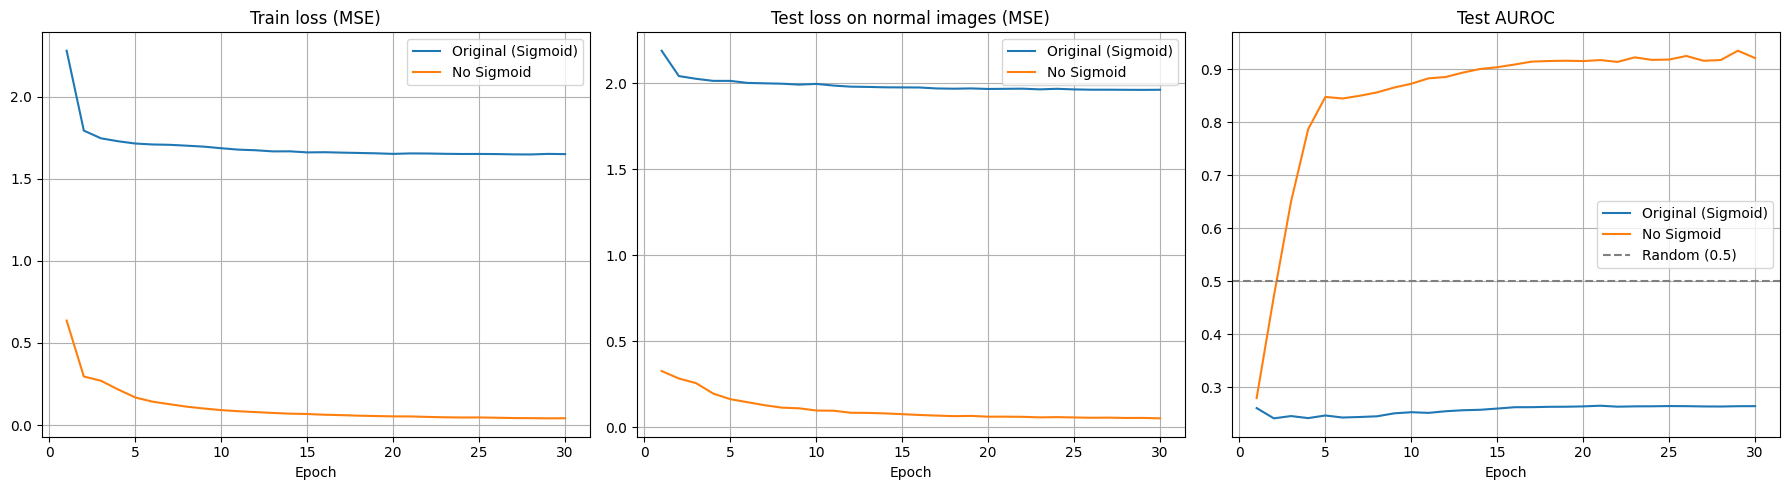

Original (Sigmoid): 마지막 에폭 AUROC 0.2645, 가장 높았던 AUROC 0.2653(에폭 21), 학습 loss 2.2794 → 1.6499
No Sigmoid: 마지막 에폭 AUROC 0.9206, 가장 높았던 AUROC 0.9345(에폭 29), 학습 loss 0.6362 → 0.0417


In [21]:
# [개인 실험] 원본에 없는 셀: 교수님이 loss만 보고 판단한 실험은 실패라고 하셔서, AutoEncoder를 다시 학습하며 에폭마다 loss와 AUROC를 같이 기록해 러닝 커브를 그려 봤다
# before/after: 원본 구조 vs 마지막 Sigmoid만 뺀 구조 (나머지 조건은 같다). 테스트셋은 관찰용으로만 쓰고 에폭 선택에는 쓰지 않는다
EPOCHS = 30  # 원본은 50에폭이지만, 원본 로그에서 loss가 25에폭 전후로 거의 멈춰서 시간 절약을 위해 30으로 줄였다
ae_train_loader, ae_test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, batch_size=16, include_mask=False)
ae_labels = np.array(ae_test_loader.dataset.labels)

def run_curve(remove_sigmoid):
    torch.manual_seed(0)
    detector = AutoEncoderAnomalyDetector()
    if remove_sigmoid:
        detector.model.decoder = detector.model.decoder[:-1]  # 마지막 Sigmoid만 뺀다 (파라미터가 없는 층이라 옵티마이저는 그대로 써도 된다)
    history = {'train_loss': [], 'test_normal_loss': [], 'test_auroc': []}
    for epoch in range(EPOCHS):
        detector.model.train()
        total = 0
        for batch in ae_train_loader:
            images = batch['image'].to(device)
            detector.optimizer.zero_grad()
            loss = detector.criterion(detector.model(images), images)
            loss.backward()
            detector.optimizer.step()
            total += loss.item()
        detector.model.eval()
        scores = []
        with torch.no_grad():
            for batch in ae_test_loader:
                images = batch['image'].to(device)
                errors = F.mse_loss(detector.model(images), images, reduction='none').view(images.size(0), -1).mean(dim=1)
                scores.extend(errors.cpu().numpy())
        scores = np.array(scores)
        history['train_loss'].append(total / len(ae_train_loader))
        history['test_normal_loss'].append(scores[ae_labels == 0].mean())
        history['test_auroc'].append(roc_auc_score(ae_labels, scores))
        if epoch % 5 == 4 or epoch == 0:
            print(f"{'Sigmoid 제거' if remove_sigmoid else '원본 구조'} 에폭 {epoch + 1:2d}: 학습 loss {history['train_loss'][-1]:.4f}, "
                  f"테스트 정상 loss {history['test_normal_loss'][-1]:.4f}, 테스트 AUROC {history['test_auroc'][-1]:.4f}")
    return history

curves = {'Original (Sigmoid)': run_curve(False), 'No Sigmoid': run_curve(True)}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, h in curves.items():
    epochs = range(1, EPOCHS + 1)
    axes[0].plot(epochs, h['train_loss'], label=name)
    axes[1].plot(epochs, h['test_normal_loss'], label=name)
    axes[2].plot(epochs, h['test_auroc'], label=name)
axes[0].set_title('Train loss (MSE)')
axes[1].set_title('Test loss on normal images (MSE)')
axes[2].set_title('Test AUROC')
axes[2].axhline(0.5, color='gray', linestyle='--', label='Random (0.5)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

for name, h in curves.items():
    best = int(np.argmax(h['test_auroc']))
    print(f"{name}: 마지막 에폭 AUROC {h['test_auroc'][-1]:.4f}, 가장 높았던 AUROC {h['test_auroc'][best]:.4f}(에폭 {best + 1}), "
          f"학습 loss {h['train_loss'][0]:.4f} → {h['train_loss'][-1]:.4f}")

In [22]:
# [개인 실험] 원본에 없는 셀: PaDiM 결과가 실행할 때마다 달라서(1차 0.961, 2차 0.962), 그 수치를 믿을 수 있는지 보려고 시드 5개로 다시 돌려 평균과 표준편차를 구해 봤다
padim_aurocs = []
for seed in range(5):
    torch.manual_seed(seed)  # 차원 축소 행렬, 좌우 뒤집기, 순서 섞기를 모두 고정한다
    seed_padim = PaDiM(feature_extractor, d_reduced=100)
    seed_padim.fit(ae_train_loader)
    seed_scores, _ = seed_padim.predict(ae_test_loader)
    padim_aurocs.append(roc_auc_score(ae_labels, seed_scores))
    print(f"시드 {seed}: AUROC {padim_aurocs[-1]:.4f}")
    del seed_padim
    torch.cuda.empty_cache()

print(f"\nPaDiM AUROC 평균 {np.mean(padim_aurocs):.4f} ± 표준편차 {np.std(padim_aurocs):.4f} "
      f"(최소 {min(padim_aurocs):.4f}, 최대 {max(padim_aurocs):.4f})")

PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:07<00:00,  6.88it/s]


전체 특징 크기: torch.Size([630336, 1536])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)


이상 탐지 중: 100%|██████████| 19/19 [00:20<00:00,  1.10s/it]


시드 0: AUROC 0.9535
PaDiM 훈련 시작...


...

시드 3: AUROC 0.9640
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:07<00:00,  7.18it/s]


전체 특징 크기: torch.Size([630336, 1536])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)


이상 탐지 중: 100%|██████████| 19/19 [00:20<00:00,  1.10s/it]

시드 4: AUROC 0.9638

PaDiM AUROC 평균 0.9601 ± 표준편차 0.0041 (최소 0.9535, 최대 0.9640)


CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
학습 804장 / 검증 150장(불량 50) / 최종 테스트 151장(불량 50)
시드 0: [픽셀 평균] 최적 에폭 41, 최종 테스트 AUROC 0.9442 | [상위 1%] 최적 에폭 51, 최종 테스트 AUROC 0.9394
시드 1: [픽셀 평균] 최적 에폭 46, 최종 테스트 AUROC 0.9339 | [상위 1%] 최적 에폭 52, 최종 테스트 AUROC 0.9311
시드 2: [픽셀 평균] 최적 에폭 26, 최종 테스트 AUROC 0.9275 | [상위 1%] 최적 에폭 49, 최종 테스트 AUROC 0.9095
시드 3: [픽셀 평균] 최적 에폭 45, 최종 테스트 AUROC 0.9305 | [상위 1%] 최적 에폭 57, 최종 테스트 AUROC 0.9372
시드 4: [픽셀 평균] 최적 에폭 53, 최종 테스트 AUROC 0.9364 | [상위 1%] 최적 에폭 32, 최종 테스트 AUROC 0.9469


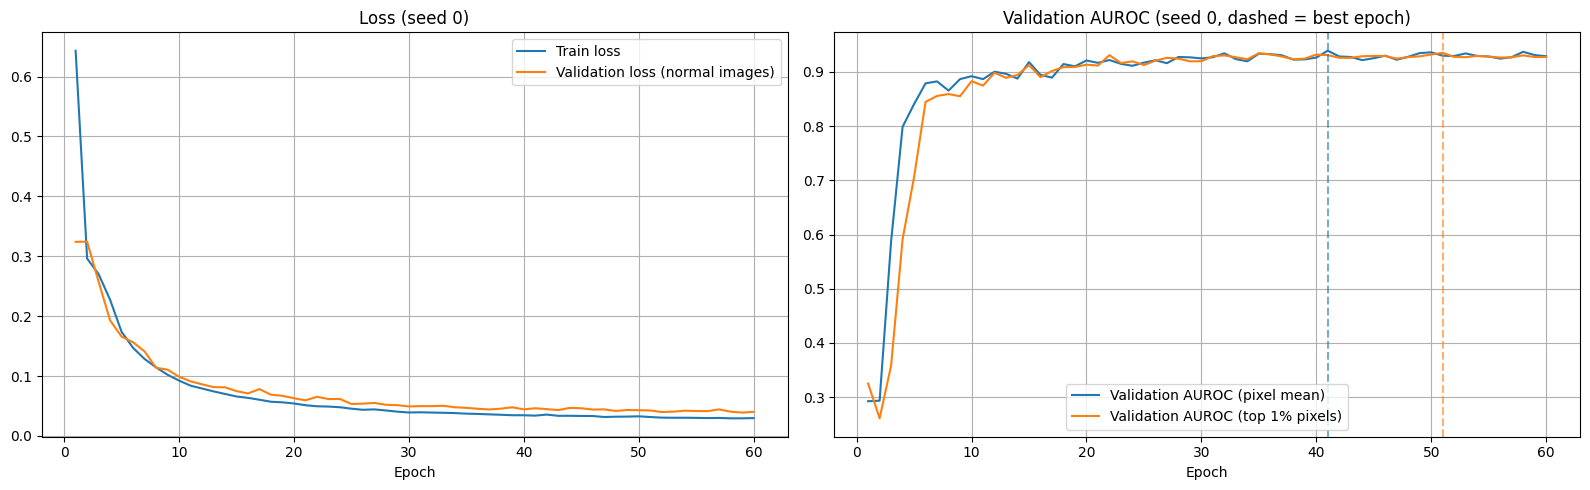

픽셀 오차 평균: 최종 테스트 AUROC 평균 0.9345 ± 0.0057 (최소 0.9275, 최대 0.9442), 고른 에폭 [41, 46, 26, 45, 53]
상위 1% 픽셀 평균: 최종 테스트 AUROC 평균 0.9328 ± 0.0127 (최소 0.9095, 최대 0.9469), 고른 에폭 [51, 52, 49, 57, 32]


In [11]:
# [개인 실험] 원본에 없는 셀: 위 실험에서 가장 좋았던 Sigmoid 제거 AutoEncoder를 교수님 기준대로 제대로 최적화하고, 시드 평균으로 성능을 확인해 봤다
# 1) 테스트셋(정상 201 + 불량 100)을 비율을 유지한 채 검증용 절반 / 최종 테스트용 절반으로 나눈다. 최적 에폭은 검증 AUROC로 고르고, 최종 테스트는 고른 모델로 한 번만 잰다
# 2) 과적합 지점을 보려고 60에폭까지 학습하고, 시드 5개로 반복해 평균 ± 표준편차를 낸다
# 3) 이상 점수를 '전체 픽셀 오차 평균'(원본 방식)과 '오차가 큰 상위 1% 픽셀 평균' 두 가지로 비교한다 (작은 결함이 평균에 묻히는지 확인)
from sklearn.model_selection import train_test_split

EPOCHS = 60
SEEDS = [0, 1, 2, 3, 4]

_, plain_transform = get_visa_transforms()  # 정규화까지만 하는 변환. 좌우 뒤집기는 아래에서 GPU로 한다
def stack_images(dataset):
    return torch.stack([dataset[i]['image'] for i in range(len(dataset))])

train_x = stack_images(VisADataset(DATA_PATH, CATEGORY_NAME, transform=plain_transform, is_train=True)).to(device)
eval_dataset = VisADataset(DATA_PATH, CATEGORY_NAME, transform=plain_transform, is_train=False)
eval_x = stack_images(eval_dataset).to(device)
eval_y = np.array(eval_dataset.labels)
val_idx, hold_idx = train_test_split(np.arange(len(eval_y)), test_size=0.5, stratify=eval_y, random_state=0)
print(f"학습 {len(train_x)}장 / 검증 {len(val_idx)}장(불량 {eval_y[val_idx].sum()}) / 최종 테스트 {len(hold_idx)}장(불량 {eval_y[hold_idx].sum()})")

def anomaly_scores(model, x, batch_size=32):
    model.eval()
    mean_scores, top_scores = [], []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = x[i:i + batch_size]
            pixel_err = ((model(xb) - xb) ** 2).mean(dim=1).flatten(1)  # 픽셀별 복원 오차 [배치, 256*256]
            k = int(pixel_err.shape[1] * 0.01)
            mean_scores.append(pixel_err.mean(dim=1).cpu())
            top_scores.append(pixel_err.topk(k, dim=1).values.mean(dim=1).cpu())
    return {'mean': torch.cat(mean_scores).numpy(), 'top1%': torch.cat(top_scores).numpy()}

def train_one_seed(seed):
    torch.manual_seed(seed)
    model = ConvAutoEncoder().to(device)
    model.decoder = model.decoder[:-1]  # Sigmoid 제거
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = {'train_loss': [], 'val_normal_loss': [], 'val_auroc_mean': [], 'val_auroc_top1%': []}
    best = {key: (-1.0, None, 0) for key in ['mean', 'top1%']}  # (검증 AUROC, 가중치, 에폭)
    y_val = eval_y[val_idx]
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(train_x), device=device)
        total = 0.0
        for i in range(0, len(train_x), 16):
            xb = train_x[order[i:i + 16]]
            flip = torch.rand(len(xb), device=device) < 0.5  # 원본 학습 전처리의 RandomHorizontalFlip(p=0.5)과 같다
            xb = torch.where(flip[:, None, None, None], xb.flip(-1), xb)
            optimizer.zero_grad()
            loss = F.mse_loss(model(xb), xb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        val = anomaly_scores(model, eval_x[val_idx])
        history['train_loss'].append(total / len(train_x))
        history['val_normal_loss'].append(val['mean'][y_val == 0].mean())
        for key in ['mean', 'top1%']:
            auroc = roc_auc_score(y_val, val[key])
            history[f'val_auroc_{key}'].append(auroc)
            if auroc > best[key][0]:
                best[key] = (auroc, {k: v.detach().clone() for k, v in model.state_dict().items()}, epoch + 1)
    result = {}
    for key in ['mean', 'top1%']:
        model.load_state_dict(best[key][1])
        hold = anomaly_scores(model, eval_x[hold_idx])
        result[key] = {'epoch': best[key][2], 'val_auroc': best[key][0], 'test_auroc': roc_auc_score(eval_y[hold_idx], hold[key])}
    return history, result

histories, results = {}, {}
for seed in SEEDS:
    histories[seed], results[seed] = train_one_seed(seed)
    r = results[seed]
    print(f"시드 {seed}: [픽셀 평균] 최적 에폭 {r['mean']['epoch']:2d}, 최종 테스트 AUROC {r['mean']['test_auroc']:.4f} | "
          f"[상위 1%] 최적 에폭 {r['top1%']['epoch']:2d}, 최종 테스트 AUROC {r['top1%']['test_auroc']:.4f}")

h = histories[SEEDS[0]]
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(epochs, h['train_loss'], label='Train loss')
axes[0].plot(epochs, h['val_normal_loss'], label='Validation loss (normal images)')
axes[0].set_title(f'Loss (seed {SEEDS[0]})')
axes[1].plot(epochs, h['val_auroc_mean'], label='Validation AUROC (pixel mean)')
axes[1].plot(epochs, h['val_auroc_top1%'], label='Validation AUROC (top 1% pixels)')
for key, color in [('mean', 'C0'), ('top1%', 'C1')]:
    axes[1].axvline(results[SEEDS[0]][key]['epoch'], color=color, linestyle='--', alpha=0.6)
axes[1].set_title(f'Validation AUROC (seed {SEEDS[0]}, dashed = best epoch)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

for key, name in [('mean', '픽셀 오차 평균'), ('top1%', '상위 1% 픽셀 평균')]:
    aurocs = [results[s][key]['test_auroc'] for s in SEEDS]
    chosen = [results[s][key]['epoch'] for s in SEEDS]
    print(f"{name}: 최종 테스트 AUROC 평균 {np.mean(aurocs):.4f} ± {np.std(aurocs):.4f} (최소 {min(aurocs):.4f}, 최대 {max(aurocs):.4f}), 고른 에폭 {chosen}")

CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개

[시드 0] 10에폭마다 정확한 값
 에폭 | 학습 loss | 검증 loss | 검증/학습 | 검증 AUROC
    1 | 0.64323 | 0.32371 | 0.503 | 0.2946
   10 | 0.09305 | 0.10163 | 1.092 | 0.8794
   20 | 0.05384 | 0.06293 | 1.169 | 0.9188
   30 | 0.03918 | 0.04893 | 1.249 | 0.9250
   40 | 0.03446 | 0.04397 | 1.276 | 0.9306
   50 | 0.03225 | 0.04205 | 1.304 | 0.9340
   60 | 0.02966 | 0.03999 | 1.349 | 0.9254
   70 | 0.02802 | 0.03882 | 1.385 | 0.9298
   80 | 0.02697 | 0.03803 | 1.410 | 0.9386
   90 | 0.02401 | 0.03529 | 1.470 | 0.9352
  100 | 0.02436 | 0.03643 | 1.496 | 0.9238
  110 | 0.02227 | 0.03412 | 1.532 | 0.9310
  120 | 0.02246 | 0.03408 | 1.517 | 0.9304
  130 | 0.02112 | 0.03374 | 1.598 | 0.9334
  140 | 0.02096 | 0.03587 | 1.711 | 0.9230
  150 | 0.02337 | 0.03718 | 1.591 | 0.9218
  160 | 0.01960 | 0.03261 | 1.664 | 0.9350
  170 | 0.01896 | 0.03261 | 1.720 | 0.9322
  180 | 0.01848 | 0.03170 | 1.716 | 0.

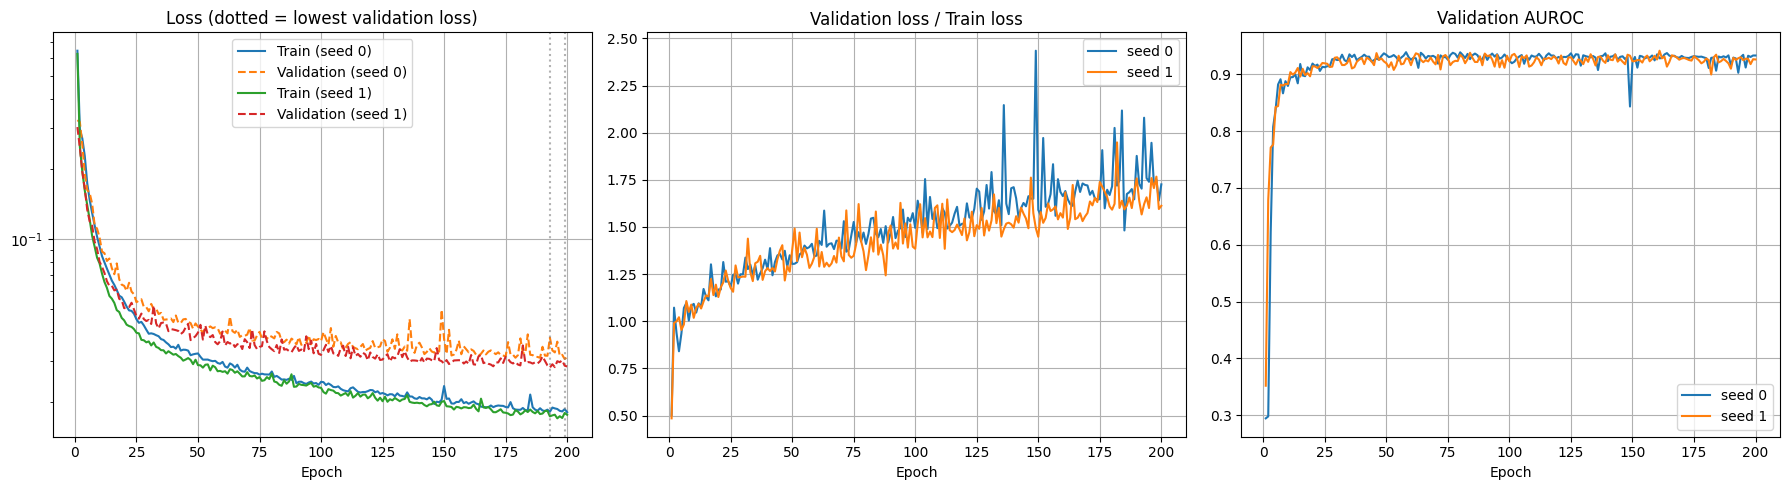

In [11]:
# [개인 실험] 원본에 없는 셀: 위 실험은 60에폭까지 과적합이 보이지 않아서, 실제로 몇 에폭부터 과적합이 나타나는지 확인하려고 200에폭까지 학습해 봤다
# 조건은 위 실험과 같다(Sigmoid 제거, 같은 검증셋). 과적합 시작 = 검증 loss가 가장 낮았던 에폭(그 뒤로는 다시 오른다)
from sklearn.model_selection import train_test_split

LONG_EPOCHS = 200
LONG_SEEDS = [0, 1]

_, plain_transform = get_visa_transforms()
def stack_images(dataset):
    return torch.stack([dataset[i]['image'] for i in range(len(dataset))])

train_x = stack_images(VisADataset(DATA_PATH, CATEGORY_NAME, transform=plain_transform, is_train=True)).to(device)
eval_dataset = VisADataset(DATA_PATH, CATEGORY_NAME, transform=plain_transform, is_train=False)
eval_x = stack_images(eval_dataset).to(device)
eval_y = np.array(eval_dataset.labels)
val_idx, hold_idx = train_test_split(np.arange(len(eval_y)), test_size=0.5, stratify=eval_y, random_state=0)  # 위 실험과 같은 나누기

def val_metrics(model):
    model.eval()
    errors = []
    with torch.no_grad():
        for i in range(0, len(val_idx), 32):
            xb = eval_x[val_idx[i:i + 32]]
            errors.append(((model(xb) - xb) ** 2).flatten(1).mean(dim=1).cpu())
    scores = torch.cat(errors).numpy()
    y = eval_y[val_idx]
    return scores[y == 0].mean(), roc_auc_score(y, scores)

def moving_average(values, window=10):
    return np.convolve(values, np.ones(window) / window, mode='valid')

long_histories = {}
for seed in LONG_SEEDS:
    torch.manual_seed(seed)
    model = ConvAutoEncoder().to(device)
    model.decoder = model.decoder[:-1]  # Sigmoid 제거
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    h = {'train_loss': [], 'val_loss': [], 'val_auroc': []}
    for epoch in range(LONG_EPOCHS):
        model.train()
        order = torch.randperm(len(train_x), device=device)
        total = 0.0
        for i in range(0, len(train_x), 16):
            xb = train_x[order[i:i + 16]]
            flip = torch.rand(len(xb), device=device) < 0.5  # 원본 학습 전처리의 RandomHorizontalFlip(p=0.5)
            xb = torch.where(flip[:, None, None, None], xb.flip(-1), xb)
            optimizer.zero_grad()
            loss = F.mse_loss(model(xb), xb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        val_loss, val_auroc = val_metrics(model)
        h['train_loss'].append(total / len(train_x))
        h['val_loss'].append(val_loss)
        h['val_auroc'].append(val_auroc)
    long_histories[seed] = h

    print(f"\n[시드 {seed}] 10에폭마다 정확한 값")
    print(" 에폭 | 학습 loss | 검증 loss | 검증/학습 | 검증 AUROC")
    for e in [1] + list(range(10, LONG_EPOCHS + 1, 10)):
        t, v, a = h['train_loss'][e - 1], h['val_loss'][e - 1], h['val_auroc'][e - 1]
        print(f" {e:4d} | {t:.5f} | {v:.5f} | {v / t:.3f} | {a:.4f}")
    best_val = int(np.argmin(h['val_loss']))
    best_val_ma = int(np.argmin(moving_average(h['val_loss']))) + 10  # 10에폭 이동평균이 가장 낮은 구간의 끝 에폭
    best_auroc = int(np.argmax(h['val_auroc']))
    print(f"→ 검증 loss 최저: {best_val + 1}에폭 ({h['val_loss'][best_val]:.5f}), 마지막 {LONG_EPOCHS}에폭 {h['val_loss'][-1]:.5f}")
    print(f"→ 검증 loss 10에폭 이동평균 최저: {best_val_ma}에폭")
    print(f"→ 검증 AUROC 최고: {best_auroc + 1}에폭 ({h['val_auroc'][best_auroc]:.4f}), 마지막 {LONG_EPOCHS}에폭 {h['val_auroc'][-1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for seed, h in long_histories.items():
    epochs = range(1, LONG_EPOCHS + 1)
    axes[0].plot(epochs, h['train_loss'], label=f'Train (seed {seed})')
    axes[0].plot(epochs, h['val_loss'], linestyle='--', label=f'Validation (seed {seed})')
    axes[1].plot(epochs, np.array(h['val_loss']) / np.array(h['train_loss']), label=f'seed {seed}')
    axes[2].plot(epochs, h['val_auroc'], label=f'seed {seed}')
    axes[0].axvline(int(np.argmin(h['val_loss'])) + 1, color='gray', linestyle=':', alpha=0.6)
axes[0].set_title('Loss (dotted = lowest validation loss)')
axes[0].set_yscale('log')
axes[1].set_title('Validation loss / Train loss')
axes[2].set_title('Validation AUROC')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

**💡 생각해 볼 점**
- PaDiM은 차원 축소 행렬, 좌우 뒤집기, 순서 섞기가 무작위라 실행할 때마다 결과가 조금씩 다르다. 개인 실험으로 시드 5개를 돌려 보니 AUROC 0.9535\~0.9640, **평균 0.960 ± 0.004**였다. 위에서 한 번 돌린 0.962도 이 범위 안이라 믿을 만한 수치다.
- **loss만 보면 안 된다**: 개인 실험으로 AutoEncoder 러닝 커브를 그려 보니, 원본 구조는 학습 loss가 2.28 → 1.65로 계속 줄었지만 테스트 AUROC는 1에폭부터 30에폭까지 0.25\~0.27에서 그대로였다. loss만 봤다면 학습이 잘 되고 있다고 착각했을 것이다.
- **before/after**: 같은 시드·같은 조건에서 마지막 `Sigmoid`만 뺐더니 AUROC가 0.28 → 0.92로 올랐다(최고 0.93, 29에폭). 바꾼 것이 이것 하나뿐이라, 입력과 출력 범위가 달라 복원이 안 됐던 것이 원인이었다고 볼 수 있다.
- 30에폭까지는 테스트 정상 loss가 계속 줄어서(0.33 → 0.05) 과적합 지점이 보이지 않았다.
- **최적화 + 시드 평균**: 그래서 Sigmoid를 뺀 구조를 60에폭까지 학습하면서, 테스트셋을 검증용 절반과 최종 테스트용 절반으로 나눴다(불량 비율 유지). 학습 데이터에는 불량이 없어서 AUROC를 재려면 불량이 섞인 검증셋이 필요하기 때문이다. 검증 AUROC가 가장 높은 에폭을 고르고, 그 모델로 최종 테스트를 한 번만 쟀다. 시드 5개 결과 **최종 테스트 AUROC 0.935 ± 0.006**(0.928\~0.944)이었다.
- 60에폭까지 검증 loss가 계속 조금씩 줄어 과적합은 나타나지 않았고, 검증 AUROC는 20에폭 전후부터 0.92\~0.93에서 평평해졌다. 그래서 시드마다 고른 에폭이 26\~53으로 흩어졌다.
- **과적합 시점 확인(200에폭)**: 60에폭까지 과적합이 안 보여서 시드 0·1로 200에폭까지 학습했다. 검증 loss는 거의 끝까지 줄어 최저가 199에폭(0.03052)·193에폭(0.02806)이었다. 즉 loss 기준 과적합은 200에폭 안에 나타나지 않았다. 대신 검증÷학습 loss 비율이 10에폭 1.092·1.018 → 200에폭 1.726·1.612로 계속 벌어져, 학습 데이터에 점점 더 맞춰지고 있다.
- 검증 AUROC는 30에폭 이후 0.92\~0.94에서 오르내릴 뿐 더 오르지 않았다(최고 58에폭 0.9388, 161에폭 0.9414). 이 과제에서는 loss보다 지표가 먼저 멈추므로, 실질적인 최적 구간은 30\~60에폭이다(위 실험에서 검증 AUROC로 고른 26\~53에폭과 맞는다).
- 작은 결함이 평균에 묻힐까 봐 이상 점수를 "오차가 큰 상위 1% 픽셀 평균"으로도 바꿔 봤지만 0.933 ± 0.013으로, 평균은 비슷하고 흔들림만 커졌다. 원본 방식(픽셀 오차 평균)을 그대로 쓰는 게 낫다.
- 이 네 실험은 런타임 사정으로 L4 GPU에서 돌렸다. AutoEncoder 최종 테스트는 테스트셋의 절반(151장)이라 PaDiM(301장 전체)과 숫자를 그대로 비교하기는 어렵다.

> ✍️ **내 코멘트**
>
> AUROC는 PaDiM 0.962, One-Class SVM 0.824, AutoEncoder 0.264가 나왔다(원본 기록 0.953 / 0.822 / 0.265). AutoEncoder는 손실이 1.64에서 멈췄고 무작위(0.5)보다도 낮았다. 학습에 15분 정도 걸렸다. PaDiM은 무작위 요소 때문에 실행마다 조금씩 달라서 개인 실험으로 시드 5개를 돌려 보니 평균 0.960 ± 0.004였다. 0.962는 믿을 만한 수치다. AutoEncoder는 러닝 커브를 그려 보니 학습 loss는 계속 줄었지만 AUROC는 처음부터 끝까지 0.26 근처였다. loss만 보고 판단하면 안 된다는 것을 직접 확인했다. 마지막 Sigmoid만 빼자 AUROC가 0.92까지 올라서, 문제는 학습 부족이 아니라 구조였다. 이 구조를 60에폭까지 학습하며 검증 AUROC로 최적 에폭을 고르고 시드 5개로 반복하니 최종 테스트 AUROC 0.935 ± 0.006이었다. 200에폭까지 늘려 보니 검증 loss는 끝까지 줄었지만(최저 199·193에폭) AUROC는 30에폭 이후 더 오르지 않아서, loss가 아니라 지표가 멈추는 30\~60에폭에서 학습을 멈추면 된다.

## 흐름 15. 결과 그래프로 비교하기
흐름 12에서 만든 그래프 4종을 그린다.

**📖 코드 설명**
- 지표 비교 막대 / ROC 곡선(왼쪽 위로 붙을수록 좋음) / PR 곡선(오른쪽 위로 붙을수록 좋음) / 정상·불량 점수 분포(두 산이 떨어져 있을수록 좋음)

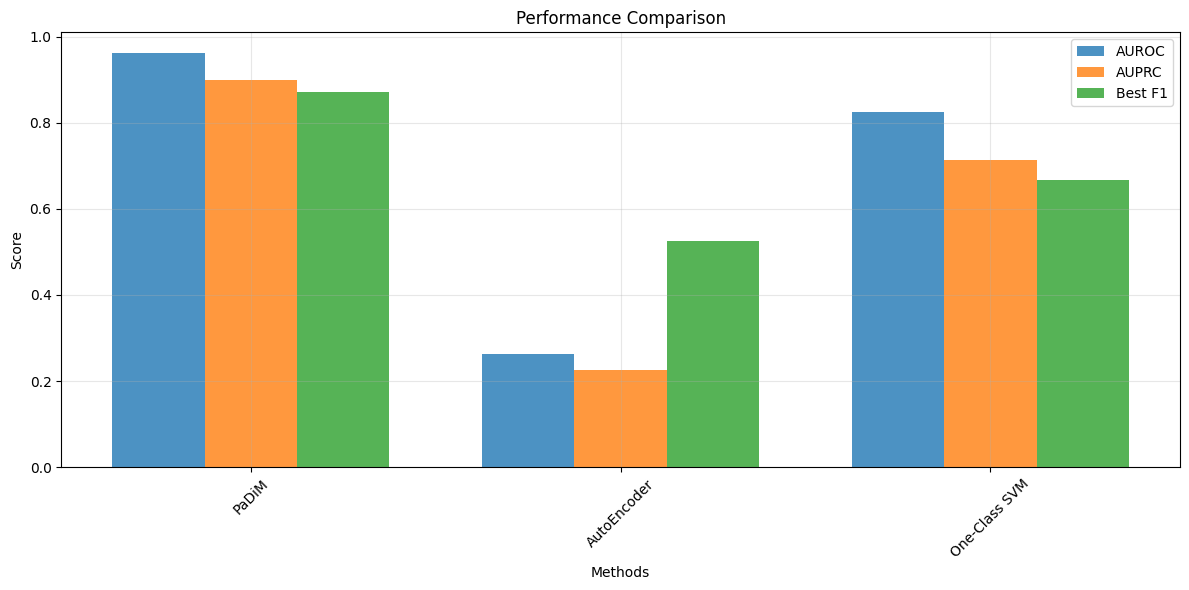

In [ ]:
system.evaluator.compare_methods()

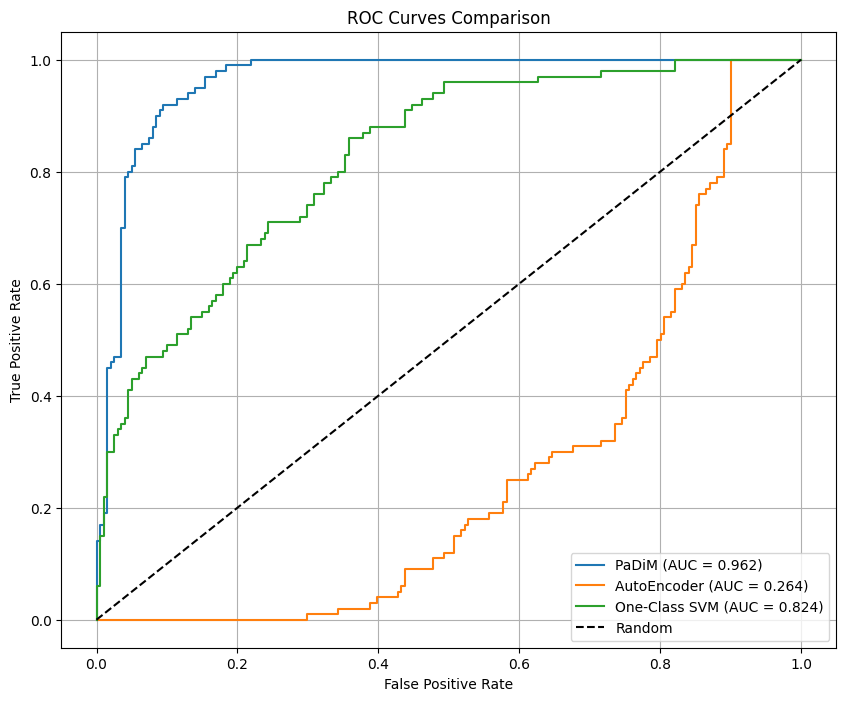

In [ ]:
system.evaluator.plot_roc_curve()

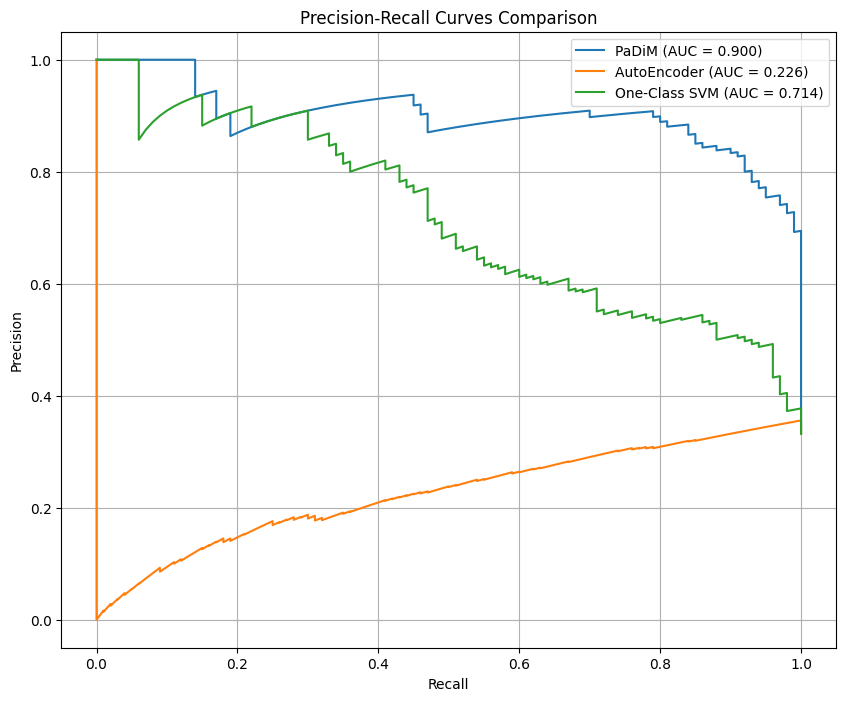

In [ ]:
system.evaluator.plot_precision_recall_curve()

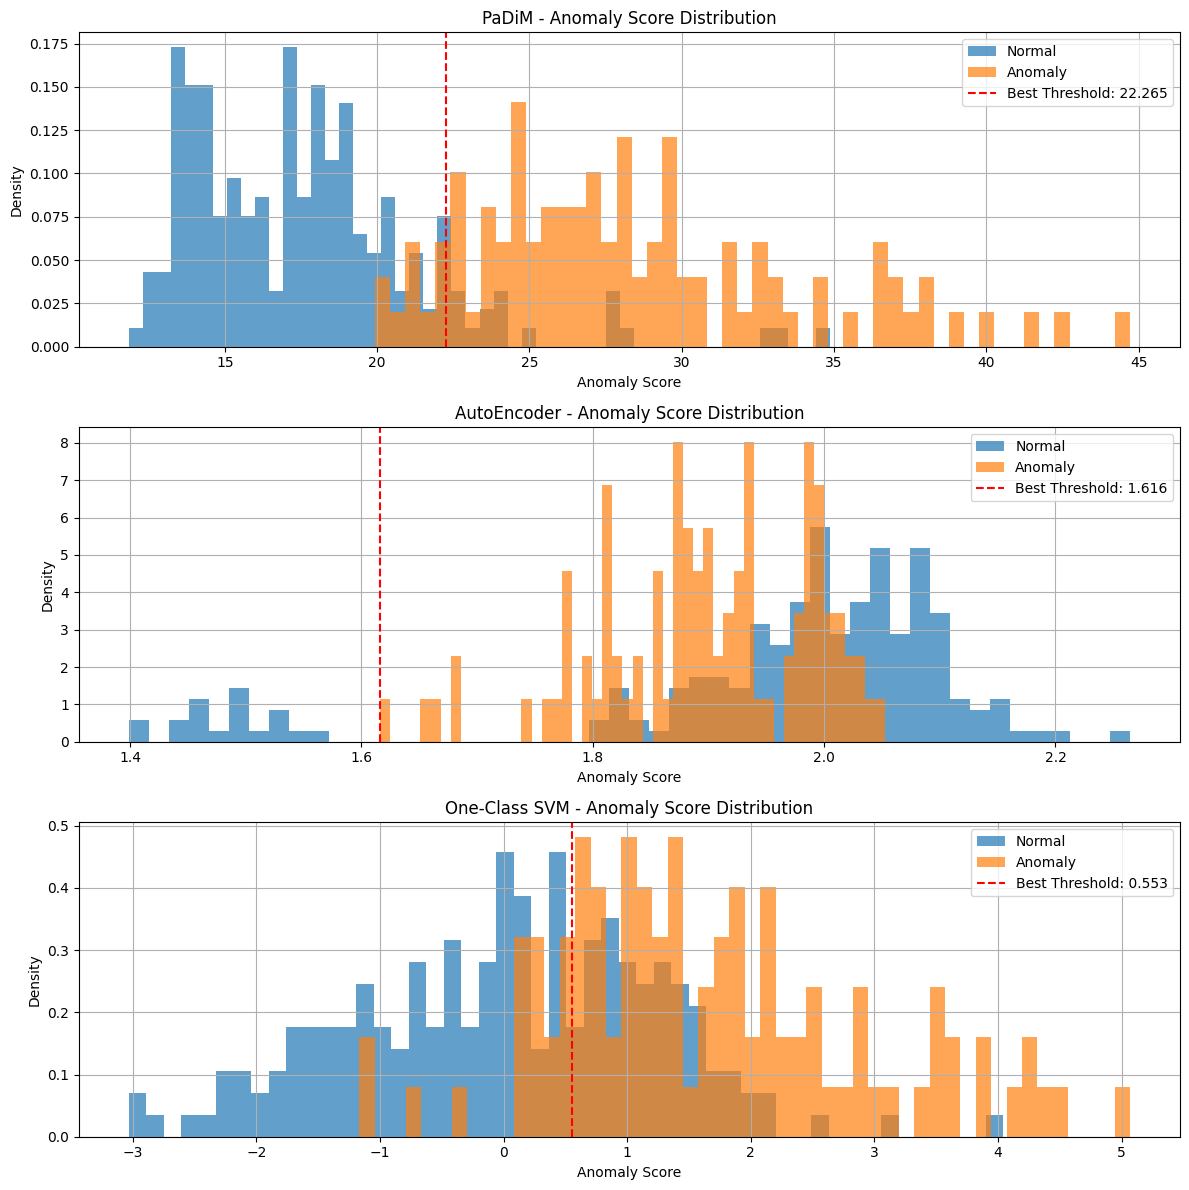

In [ ]:
system.evaluator.plot_score_distribution()

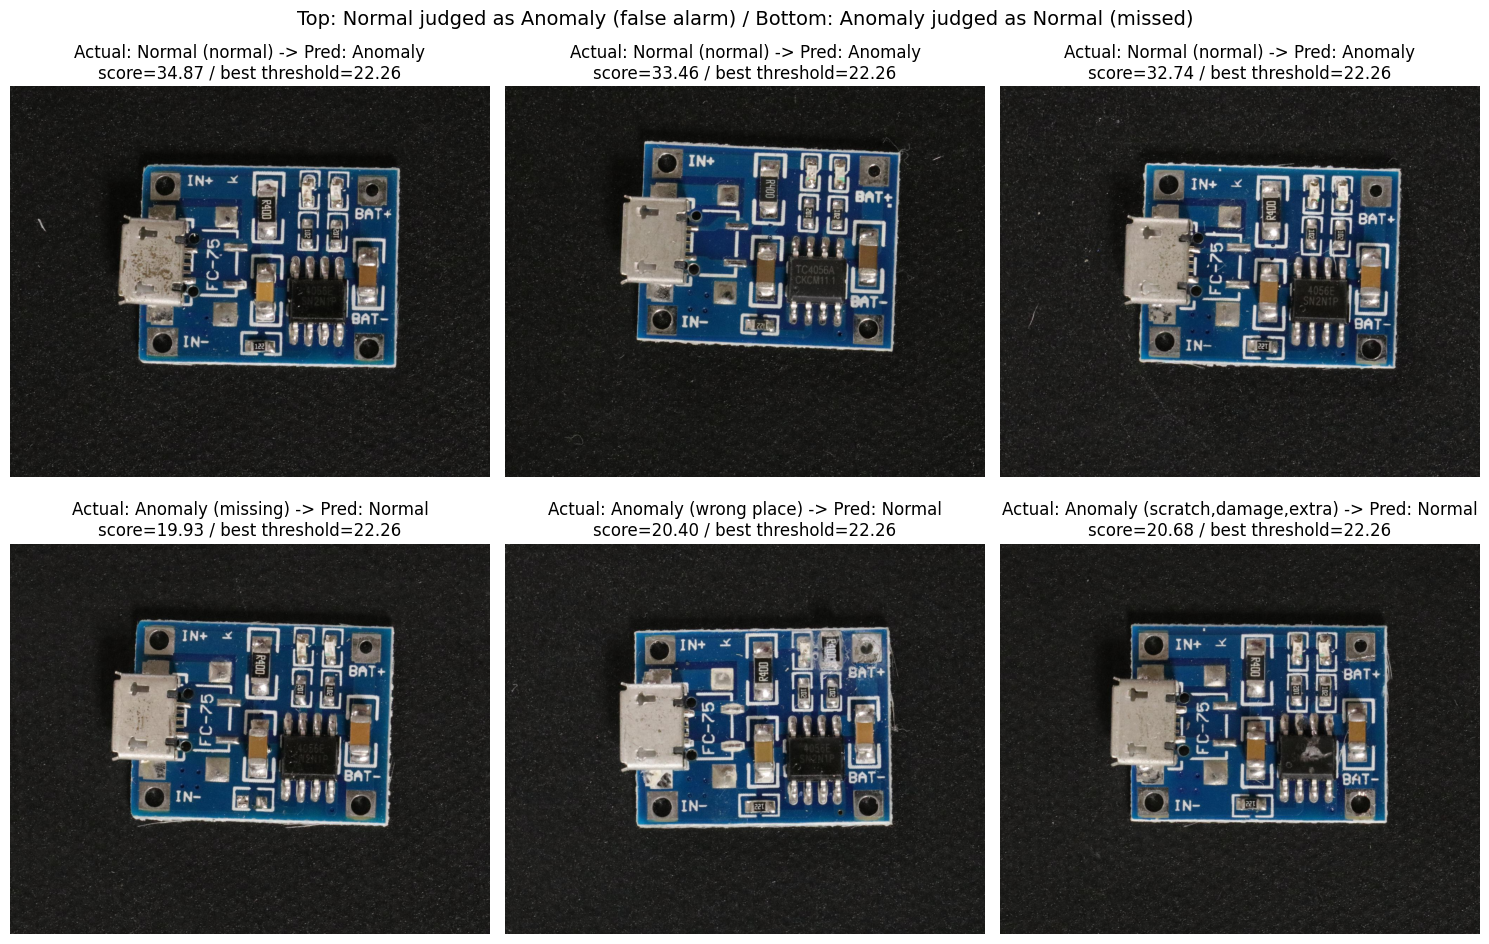

실제 정상 201장 중 19장이 불량으로 판정됨(오탐)
실제 불량 100장 중 8장이 정상으로 판정됨(미탐)
실제 정상 점수의 중앙값: 17.34
점수가 낮은 불량 19.93점은 실제 정상 이미지의 78.1%보다 높다
점수가 낮은 불량 20.40점은 실제 정상 이미지의 81.6%보다 높다
점수가 낮은 불량 20.68점은 실제 정상 이미지의 83.1%보다 높다


In [ ]:
# [개인 실험] 원본에 없는 셀: PaDiM이 틀리는 이미지는 어떻게 생겼는지 궁금해서, 점수가 가장 높은 정상 3장과 가장 낮은 불량 3장을 그려 봤다
test_dataset = system.test_loader.dataset
labels = system.test_labels
normal_idx = np.where(labels == 0)[0]
anomaly_idx = np.where(labels == 1)[0]
worst_normal = normal_idx[np.argsort(padim_scores[normal_idx])[-3:][::-1]]  # 정상인데 점수가 높은 것 (오탐 후보)
worst_anomaly = anomaly_idx[np.argsort(padim_scores[anomaly_idx])[:3]]     # 불량인데 점수가 낮은 것 (미탐 후보)
threshold = system.evaluator.results['PaDiM']['Best_Threshold']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Top: Normal judged as Anomaly (false alarm) / Bottom: Anomaly judged as Normal (missed)', fontsize=14)
for row, (indices, name) in enumerate([(worst_normal, 'Normal'), (worst_anomaly, 'Anomaly')]):
    for col, idx in enumerate(indices):
        image = Image.open(test_dataset.image_paths[idx]).convert('RGB')
        pred = 'Anomaly' if padim_scores[idx] >= threshold else 'Normal'  # 평가 도구(precision_recall_curve)와 같은 기준
        axes[row, col].imshow(image)
        axes[row, col].set_title(f"Actual: {name} ({test_dataset.defect_types[idx]}) -> Pred: {pred}\nscore={padim_scores[idx]:.2f} / best threshold={threshold:.2f}")
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

# 위 그림만으로는 알 수 없는 숫자도 궁금해서 출력해 봤다
normal_scores, anomaly_scores = padim_scores[labels == 0], padim_scores[labels == 1]
print(f"실제 정상 {len(normal_scores)}장 중 {(normal_scores >= threshold).sum()}장이 불량으로 판정됨(오탐)")
print(f"실제 불량 {len(anomaly_scores)}장 중 {(anomaly_scores < threshold).sum()}장이 정상으로 판정됨(미탐)")
print(f"실제 정상 점수의 중앙값: {np.median(normal_scores):.2f}")
for idx in worst_anomaly:
    print(f"점수가 낮은 불량 {padim_scores[idx]:.2f}점은 실제 정상 이미지의 {(normal_scores < padim_scores[idx]).mean():.1%}보다 높다")

**💡 생각해 볼 점**
- 점수 분포에서 정상과 불량이 겹치는 구간이 현장에서 오탐·미탐이 생기는 부분이다.
- 개인 실험으로 PaDiM이 틀린 이미지를 그려 봤다. 사진 제목의 `Actual`은 실제 정답, `Pred`는 모델의 판정이다(최적 임계값 22.26 이상이면 불량으로 판정).
  - **오탐 (위 3장)**: 실제로는 정상인데 점수가 32.7\~34.9점으로 임계값을 넘어서 불량으로 판정됐다. 그중 하나는 기판이 눈에 띄게 기울어져 있었다. 기판 자체에는 결함이 없어서 정답은 정상이지만, 위치마다 정상을 배우는 PaDiM에는 놓인 각도가 다른 것만으로도 "평소와 다르다"로 보였을 가능성이 크다.
  - **미탐 (아래 3장)**: 실제로는 불량인데 점수가 19.9\~20.7점으로 임계값에 조금 못 미쳐서 정상으로 판정됐다. 실험 셀 출력을 보면 이 점수는 실제 정상 이미지의 78\~83%보다 높다(실제 정상의 중앙값 17.34). 모델이 "조금 이상하다"고는 본 경계선 사례다.
  - 실험 셀 출력: 실제 정상 201장 중 19장이 불량으로, 실제 불량 100장 중 8장이 정상으로 판정됐다. 실제 정상인데 34.9점인 사진과 실제 불량인데 19.9점인 사진이 함께 있어서, 임계값을 어디에 두어도 둘 중 하나는 틀린다. 임계값 하나로 둘을 완벽히 나눌 수는 없다.

> ✍️ **내 코멘트**
>
> 그래프에서도 PaDiM이 세 지표 모두 가장 높고, AutoEncoder는 ROC 곡선이 대각선 아래에 있다. AUROC가 0.5보다 낮다는 건 아무것도 모르는 게 아니라 정상과 불량을 거꾸로 맞혔다는 뜻이다(점수를 뒤집으면 1 - 0.264 = 약 0.74). 개인 실험에서 실제 정상인데 34.9점인 사진과 실제 불량인데 19.9점인 사진이 나와서, 임계값을 어디에 두어도 둘 중 하나는 틀린다. 임계값 하나로 둘을 완벽히 나눌 수는 없다.

# 파트 D. 실시간 추론 웹 앱 (PaDiM + Gradio)

## 흐름 16. 필요한 것 다시 불러오기
파트 C에서 가장 좋았던 **PaDiM**으로 웹 검사 화면을 만든다. 먼저 라이브러리, Dataset, DataLoader, 특징 추출기를 다시 정의한다.

**📖 코드 설명**
- 앞에서 만든 것과 **같은 코드**다(주석과 빈 줄만 줄었다).

### 실시간 inference

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import cv2
import numpy as np
import torchvision.models as models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings

In [ ]:
class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [ ]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 169MB/s]


**💡 생각해 볼 점**
- 따로 실행할 수 있어 보이지만, `os`, `IMG_SIZE`, `PADIM_PATCH_SIZE` 같은 앞의 정의가 필요해서 처음부터 실행해야 한다.

> ✍️ **내 코멘트**
>
> 파트 D에서 쓰려고 앞의 클래스와 함수를 다시 정의한다. 하지만 앞에서 정한 설정값이 필요해서 따로 실행할 수는 없다.

## 흐름 17. 이상 위치 지도를 돌려주는 PaDiM
흐름 9의 PaDiM을 실시간 추론용으로 고친 버전이다.

**📖 코드 설명**
- `predict`가 DataLoader 대신 **이미지 텐서를 직접** 받는다(웹에서 올린 사진 한 장을 바로 넣기 위해).
- 이상 점수와 함께 **28×28 이상 지도**도 돌려준다. 이 지도가 히트맵이 된다(강의 34쪽 "이상 점수 맵").

In [ ]:
# --- PaDiM 클래스 (사용자 제공 코드, predict 수정) ---
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100, padim_patch_size=PADIM_PATCH_SIZE):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.padim_patch_size = padim_patch_size
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        print("PaDiM 훈련 시작...")
        all_features = []
        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)
            with torch.no_grad():
                features = self.feature_extractor(images)
                for i in range(images.size(0)):
                    img_features = []
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                        img_features.append(feat_patches)
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        num_patches = self.padim_patch_size * self.padim_patch_size
        for patch_idx in range(num_patches):
            patch_features = all_features[patch_idx::num_patches]
            mean = torch.mean(patch_features, dim=0)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4
            try:
                inv_cov = torch.linalg.inv(cov)
            except RuntimeError:
                inv_cov = torch.linalg.pinv(cov)
            self.means.append(mean)
            self.inv_covariances.append(inv_cov)
        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, images_tensor): # DataLoader 대신 이미지 텐서를 직접 받도록 수정
        """테스트 이미지 텐서에 대한 이상 점수 및 이상 맵 계산"""
        all_image_scores = []
        all_anomaly_maps = []

        with torch.no_grad():
            features = self.feature_extractor(images_tensor) # 이미지 텐서 바로 사용

            for i in range(images_tensor.size(0)):
                img_features = []
                for layer_name, feat in features.items():
                    single_feat = feat[i:i+1]
                    feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                    feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                    img_features.append(feat_patches)

                combined_features = torch.cat(img_features, dim=1)

                if self.projection_matrix is not None:
                    combined_features = torch.mm(combined_features, self.projection_matrix)

                patch_scores_for_image = []
                num_patches = self.padim_patch_size * self.padim_patch_size
                for patch_idx in range(num_patches):
                    diff = combined_features[patch_idx] - self.means[patch_idx]
                    mahal_dist = torch.sqrt(torch.mm(
                        torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                        diff.unsqueeze(1)
                    )).item()
                    patch_scores_for_image.append(mahal_dist)

                all_image_scores.append(max(patch_scores_for_image))

                # 이상 맵 생성 (28x28 형태로)
                anomaly_map = torch.tensor(patch_scores_for_image).reshape(self.padim_patch_size, self.padim_patch_size).cpu().numpy()
                all_anomaly_maps.append(anomaly_map)

        return np.array(all_image_scores), np.array(all_anomaly_maps)

**💡 생각해 볼 점**
- 위치별로 하나씩 계산하는 반복문은 그대로라, "실시간"이라는 이름에 비해 느리다.

> ✍️ **내 코멘트**
>
> 이미지를 바로 받아서 이상 점수와 28×28 이상 지도를 돌려준다. 이 지도가 히트맵이 된다. 위치를 하나씩 계산하는 반복문은 그대로라 실시간이라고 하기엔 느리다.

## 흐름 18. 전처리 다시 정의
`get_visa_transforms()`를 다시 만든다.

**📖 코드 설명**
- 흐름 4와 달리 **좌우 뒤집기를 뺐다**. 위치마다 정상을 배우는 PaDiM에는 이쪽이 맞다.

In [ ]:
def get_visa_transforms():
    """
    VisA 데이터셋에 적용할 이미지 변환(transform)을 반환합니다.
    실제 데이터셋과 모델에 맞게 이 부분을 수정해야 합니다.
    """
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])

    # 테스트 시에는 일반적으로 Augmentation을 많이 하지 않습니다.
    test_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])
    return train_transform, test_transform


**💡 생각해 볼 점**
- 파트 C의 PaDiM은 뒤집기가 들어간 데이터로 배워서, 파트 C의 AUROC를 파트 D 모델의 성능으로 볼 수는 없다.

> ✍️ **내 코멘트**
>
> 전처리를 다시 정의하면서 좌우 뒤집기를 뺐다. 그래서 파트 C와 파트 D의 PaDiM은 조건이 달라 성능을 바로 비교할 수 없다.

## 흐름 19. PaDiM 학습하고 파일로 저장하기
**layer1\~3** 특징으로 PaDiM을 학습하고, 결과를 `padim_outputs/padim_model_state.pkl`에 저장한다.

**📖 코드 설명**
- layer1까지 써서 256 + 512 + 1024 = **1,792차원**. 가장 세밀한(64×64) layer1을 더해서 작은 결함을 더 잘 볼 것으로 기대하는 설정이다.
- 평균·역공분산·차원 축소 행렬만 저장한다. 특징 추출기는 사전학습 모델이라 다시 불러오면 똑같다.

In [ ]:
# --- 데이터셋 경로 및 카테고리 설정 ---
# !!! 중요: 이 경로를 실제 VisA 데이터셋이 있는 경로로 수정해야 합니다 !!!
# 예시: DATA_PATH = "/path/to/your/visa_dataset"
# VisA 데이터셋이 없다면, 아래 예시처럼 직접 폴더를 만들고 소수의 이미지를 넣어 테스트할 수 있습니다.
# DATA_PATH/CATEGORY_NAME/train/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/anomaly_type1/img1.png, img2.png ...
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

# 결과물 저장 경로
OUTPUT_DIR = "padim_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
SAVED_MODEL_PATH = os.path.join(OUTPUT_DIR, "padim_model_state.pkl")

print(f"Data path set to: {DATA_PATH}")
print(f"Make sure you have data in the respective folders, e.g., {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
print("-" * 30)


# --- 모델 초기화 ---
print("FeatureExtractor 초기화 중...")
# 사용할 CNN 백본과 추출할 레이어 설정
# 예: wide_resnet50_2의 layer1, layer2, layer3 특징 사용
feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)
print("PaDiM 모델 초기화 중...")
padim_model = PaDiM(feature_extractor=feature_extractor, d_reduced=D_REDUCED)

# --- 데이터 로더 생성 ---
print("데이터 로더 생성 중...")
try:
    train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE)

    # 훈련 데이터셋에 이미지가 있는지 확인
    if len(train_loader.dataset) == 0:
        print(f"훈련 데이터셋에 이미지가 없습니다! 경로를 확인하세요: {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
        # 이 경우 학습을 진행할 수 없으므로, 예외를 발생시키거나 중단할 수 있습니다.
        # raise ValueError("훈련 데이터가 비어있습니다. 학습을 진행할 수 없습니다.")
    else:
        print(f"훈련 데이터셋 크기: {len(train_loader.dataset)}")
        print(f"테스트 데이터셋 크기: {len(test_loader.dataset)}")

        # --- PaDiM 모델 학습 ---
        padim_model.fit(train_loader)

        # --- 학습된 모델 저장 ---
        print(f"학습된 PaDiM 모델을 '{SAVED_MODEL_PATH}'에 저장합니다...")
        # PaDiM 클래스 전체를 저장하거나, 필요한 attribute만 저장할 수 있습니다.
        # 여기서는 주요 attribute들을 딕셔너리 형태로 저장합니다.
        padim_state = {
            'means': padim_model.means,
            'inv_covariances': padim_model.inv_covariances,
            'projection_matrix': padim_model.projection_matrix,
            'd_reduced': padim_model.d_reduced,
            'padim_patch_size': padim_model.padim_patch_size
            # FeatureExtractor는 구조가 동일하므로 저장하지 않고 추론 시 새로 생성
        }
        with open(SAVED_MODEL_PATH, 'wb') as f:
            pickle.dump(padim_state, f)
        print("모델 저장 완료.")

except FileNotFoundError as e:
    print(f"데이터 경로 오류: {e}")
    print("DATA_PATH 및 CATEGORY_NAME을 올바르게 설정하고, 해당 경로에 이미지 파일이 있는지 확인해주세요.")
except Exception as e:
    print(f"학습 중 오류 발생: {e}")



Data path set to: ./VisA
Make sure you have data in the respective folders, e.g., ./VisA/pcb4/train/good
------------------------------
FeatureExtractor 초기화 중...
PaDiM 모델 초기화 중...
데이터 로더 생성 중...
CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
훈련 데이터셋 크기: 804
테스트 데이터셋 크기: 301
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 101/101 [00:17<00:00,  5.73it/s]


전체 특징 크기: torch.Size([630336, 1792])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)
학습된 PaDiM 모델을 'padim_outputs/padim_model_state.pkl'에 저장합니다...
모델 저장 완료.


**💡 생각해 볼 점**
- 안내 문구의 `train/good` 경로는 MVTec 데이터셋 형식이라 VisA 구조와 맞지 않는다.
- 원본은 이 모델을 따로 평가하지 않는다(흐름 20의 🧪 개인 실험에서 확인해 봤다).

> ✍️ **내 코멘트**
>
> layer1까지 써서 1,792차원으로 PaDiM을 학습하고 pkl 파일로 저장했다. 안내 문구의 `train/good` 경로는 VisA 폴더 구조와 맞지 않는다.

## 흐름 20. 저장한 모델 불러오기와 추론 함수
저장한 파일에서 PaDiM을 다시 만들고, 웹 화면에서 부를 추론 함수를 정의한다.

**📖 코드 설명**
- `load_padim_model_state`: pkl을 읽어 **학습 없이** 바로 추론할 수 있게 한다.
- `padim_inference_gradio`: 사진 한 장 → 이상 점수와 지도 → 히트맵(파랑=정상, 빨강=이상) → 원본에 겹치기 → 점수가 **15보다 크면 비정상**

In [ ]:
# --- 저장된 PaDiM 모델 로드 함수 ---
def load_padim_model_state(filepath, feature_extractor_instance):
    if not os.path.exists(filepath):
        print(f"저장된 모델 파일이 없습니다: {filepath}")
        return None

    with open(filepath, 'rb') as f:
        padim_state = pickle.load(f)

    # 새 PaDiM 인스턴스를 만들고 상태를 로드
    loaded_model = PaDiM(feature_extractor_instance,
                           d_reduced=padim_state.get('d_reduced', 100), # 기본값 설정
                           padim_patch_size=padim_state.get('padim_patch_size', PADIM_PATCH_SIZE)) # 기본값 설정
    loaded_model.means = padim_state['means']
    loaded_model.inv_covariances = padim_state['inv_covariances']
    loaded_model.projection_matrix = padim_state['projection_matrix']

    print(f"'{filepath}'에서 PaDiM 모델 상태 로드 완료.")
    return loaded_model

# --- Gradio 추론 함수 ---
# 모델 로드는 Gradio 앱 시작 시 한 번만 수행하도록 전역 변수로 관리
gradio_feature_extractor = None
gradio_padim_model = None
_, gradio_test_transform = get_visa_transforms() # 테스트용 변환 사용

def initialize_gradio_models():
    global gradio_feature_extractor, gradio_padim_model
    if gradio_feature_extractor is None:
        print("Gradio: FeatureExtractor 초기화 중...")
        gradio_feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)

    if gradio_padim_model is None:
        print("Gradio: 저장된 PaDiM 모델 로드 중...")
        gradio_padim_model = load_padim_model_state(SAVED_MODEL_PATH, gradio_feature_extractor)
        if gradio_padim_model is None:
            print("Gradio: 모델 로드 실패! 학습을 먼저 실행하거나 모델 경로를 확인하세요.")
            # Gradio 인터페이스 실행 전에 모델이 로드되었는지 확인 필요

# Gradio 앱 시작 전에 모델 초기화 시도
initialize_gradio_models()


def padim_inference_gradio(input_image_pil):
    """Gradio 인터페이스를 위한 추론 함수"""
    if gradio_padim_model is None:
        return "모델이 로드되지 않았습니다. 학습을 먼저 실행하거나 모델 경로를 확인하세요.", None, None

    # PIL 이미지를 PyTorch 텐서로 변환 및 전처리
    img_tensor = gradio_test_transform(input_image_pil).unsqueeze(0).to(device) # 배치 차원 추가

    # PaDiM 모델로 추론
    image_score, anomaly_map_array = gradio_padim_model.predict(img_tensor)

    # 결과 처리
    score = image_score[0] # 단일 이미지이므로 첫 번째 점수 사용
    anomaly_map_single = anomaly_map_array[0] # 단일 이미지의 이상 맵

    # 이상 맵 시각화 (Heatmap)
    # 0-1 범위로 정규화 후 컬러맵 적용
    anomaly_map_normalized = (anomaly_map_single - np.min(anomaly_map_single)) / \
                             (np.max(anomaly_map_single) - np.min(anomaly_map_single) + 1e-6)

    heatmap_img = cv2.applyColorMap(np.uint8(255 * anomaly_map_normalized), cv2.COLORMAP_JET)
    heatmap_img = cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB) # Matplotlib/Gradio용 RGB

    # 원본 이미지에 히트맵 오버레이 (PIL 이미지를 NumPy로 변환 후 사용)
    original_np = np.array(input_image_pil.resize((IMG_SIZE, IMG_SIZE)))
    if original_np.shape[2] == 4: # RGBA -> RGB
        original_np = original_np[..., :3]

    heatmap_resized = cv2.resize(heatmap_img, (original_np.shape[1], original_np.shape[0]))
    overlayed_image = cv2.addWeighted(original_np, 0.6, heatmap_resized, 0.4, 0)

    result_text = f"이상 점수(Anomaly Score): {score:.4f}"
    if score > 15: # 임계값 예시 (데이터와 모델에 따라 크게 달라짐, 튜닝 필요!)
        result_text += "\n판정: 비정상 (Anomaly)"
    else:
        result_text += "\n판정: 정상 (Normal)"

    return result_text, heatmap_img, overlayed_image



Gradio: FeatureExtractor 초기화 중...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1`. You can also use `weights=Wide_ResNet50_2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Gradio: 저장된 PaDiM 모델 로드 중...
'padim_outputs/padim_model_state.pkl'에서 PaDiM 모델 상태 로드 완료.


In [ ]:
# 🧪 [개인 실험] 원본에 없는 셀: 판정 기준 15가 맞는 값인지 궁금해서, 테스트 이미지 전부를 이 기준으로 판정해 봤다
all_scores, all_labels = [], []
for batch in tqdm(test_loader, desc="테스트셋 점수 계산"):
    scores, _ = gradio_padim_model.predict(batch['image'].to(device))
    all_scores.extend(scores)
    all_labels.extend(batch['label'].numpy())
all_scores, all_labels = np.array(all_scores), np.array(all_labels)

pred = all_scores > 15
normal, anomaly = all_labels == 0, all_labels == 1
print(f"이 모델(layer1~3)의 AUROC: {roc_auc_score(all_labels, all_scores):.4f}")
print(f"정상 점수 범위: {all_scores[normal].min():.2f} ~ {all_scores[normal].max():.2f}")
print(f"불량 점수 범위: {all_scores[anomaly].min():.2f} ~ {all_scores[anomaly].max():.2f}")
print(f"임계값 15 → 불량 {anomaly.sum()}장 중 {pred[anomaly].sum()}장을 잡음 (재현율 {pred[anomaly].mean():.1%})")
print(f"임계값 15 → 정상 {normal.sum()}장 중 {pred[normal].sum()}장을 불량으로 잘못 판정 (오탐률 {pred[normal].mean():.1%})")

테스트셋 점수 계산: 100%|██████████| 38/38 [00:26<00:00,  1.46it/s]

이 모델(layer1~3)의 AUROC: 0.9758
정상 점수 범위: 12.35 ~ 34.01
불량 점수 범위: 21.97 ~ 60.90
임계값 15 → 불량 100장 중 100장을 잡음 (재현율 100.0%)
임계값 15 → 정상 201장 중 135장을 불량으로 잘못 판정 (오탐률 67.2%)


**💡 생각해 볼 점**
- 임계값 15는 "예시"다. 🧪 개인 실험으로 테스트셋 전체를 판정해 보니 실제 불량 100장은 모두 불량으로 판정했지만, 실제 정상 201장 중 135장(67.2%)도 불량으로 판정했다(오탐). 실제 정상 이미지의 점수가 12\~34점이라 15는 너무 낮다. 흐름 15처럼 데이터로 정한 값을 써야 한다.
- 같은 실험에서 이 모델(layer1\~3)의 AUROC는 0.976으로 파트 C(layer2\~3, 0.962)보다 조금 높았다. 다만 좌우 뒤집기도 빠졌기 때문에 layer1만의 효과라고 단정하긴 어렵다.
- 히트맵을 이미지마다 최솟값\~최댓값으로 정규화해서, 정상 이미지도 어딘가는 빨갛게 보인다. 색만 보지 말고 점수와 함께 봐야 한다.

> ✍️ **내 코멘트**
>
> 저장한 모델을 불러와 학습 없이 바로 추론한다. 임계값 15로 판정하면 실제 불량은 다 잡지만 실제 정상의 67%도 불량으로 판정해서, 실제로 쓰려면 임계값을 다시 정해야 한다.

## 흐름 21. Gradio 웹 화면 띄우기
**Gradio**로 이미지를 올리면 판정 결과·히트맵·겹친 이미지를 보여 주는 웹 화면을 만든다. (강의 목표: "OpenCV와 Gradio를 활용한 실시간 비전 시스템 구축")

**📖 코드 설명**
- `gr.Interface(fn=..., inputs=..., outputs=...)`: 함수 하나를 웹 화면으로 감싼다. 입력은 이미지 1개, 출력은 글자 1개 + 이미지 2개
- `iface.launch(share=True)`: 셀 아래에 화면이 뜨고, `https://....gradio.live` **공개 주소**도 만들어진다(1주일 유효).

In [ ]:
import gradio as gr

In [ ]:
# --- Gradio 인터페이스 생성 및 실행 ---
if gradio_padim_model is not None: # 모델이 성공적으로 로드된 경우에만 인터페이스 실행
    iface = gr.Interface(
        fn=padim_inference_gradio,
        inputs=gr.Image(type="pil", label="검사할 이미지 업로드"),
        outputs=[
            gr.Textbox(label="결과"),
            gr.Image(type="numpy", label="이상 맵 (Anomaly Map Heatmap)"),
            gr.Image(type="numpy", label="오버레이된 이미지 (Overlayed Image)")
        ],
        title="PaDiM 이상 탐지 시스템 (VisA Dataset)",
        description="이미지를 업로드하여 정상/비정상 여부를 판별하고 이상 영역을 확인합니다. (백본: WideResNet50)",
        examples=[ # 예제 이미지가 있다면 경로를 지정 (Gradio에서 클릭 가능)
        ] if os.path.exists(os.path.join(DATA_PATH, CATEGORY_NAME, "test")) else None # 예제 폴더가 있을 때만 추가
    )

    iface.launch(share=True) # share=True로 하면 외부에서 접속 가능한 링크 생성 (주의해서 사용)
else:
    print("-" * 50)
    print("!!! PaDiM 모델이 로드되지 않았습니다. Gradio 인터페이스를 시작할 수 없습니다. !!!")
    print("!!! 셀 7에서 모델 학습 및 저장이 성공적으로 완료되었는지, SAVED_MODEL_PATH가 올바른지 확인해주세요. !!!")
    print("-" * 50)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6cbecd2ebfd809a32a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**💡 생각해 볼 점**
- `share=True` 주소는 **누구나 접속할 수 있다**. 회사 데이터라면 공개 주소 없이 쓰거나 `auth=`로 비밀번호를 걸어야 한다.
- 사진을 한 장씩 올리는 방식이라, 생산 라인처럼 계속 검사하려면 카메라 프레임을 받아 반복하는 코드가 필요하다.

> ✍️ **내 코멘트**
>
> Gradio로 추론 함수를 웹 화면으로 만든다. `share=True`는 공개 주소가 생겨서 회사 데이터라면 조심해야 한다. 사진을 한 장씩 올리는 방식이라, 생산 라인에서 쓰려면 카메라 영상을 계속 받아 검사하는 코드가 필요하다.